# Local Stiffness: Time vs Precision

This notebook measures the time required to obtain local element stiffness matrices $K_e$ from an input STL and compares 128³ methods with a 512³ QuESo reference.

**Timing boundary:** source STL read through final active-cell $K_e$ matrices. QuESo preprocessing, NN input preparation, classification, and inference are included. Global sparse assembly and displacement solves are excluded.

**Precision:** volume-weighted relative Frobenius error on 128³ physical cells against the restriction of the 512³ QuESo reference. The report also retains median and p95 cellwise errors so small-volume cells cannot dominate the headline.

In [2]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError("Open this notebook from the repository root or a descendant directory.")

OUTPUT_DIR = ROOT / "clean_simulation" / "outputs" / "local_stiffness_convergence"
SOURCE_STL = ROOT / "clean_simulation" / "geometries" / "crystal_0000.stl"
REFERENCE_RESOLUTION = 512
WORKING_RESOLUTION = 128
MATRIX_ERROR_EPS = 1.0e-12

REFERENCE_FILE = OUTPUT_DIR / f"crystal_0000_reference_trimmed_{REFERENCE_RESOLUTION}cubed.h5"
WORKING_QUESO_FILE = OUTPUT_DIR / f"crystal_0000_queso_matrices_{WORKING_RESOLUTION}cubed.h5"
CONVERGENCE_FILE = OUTPUT_DIR / "local_stiffness_convergence_512_reference.csv"
TIMING_FILE = OUTPUT_DIR / "time_vs_precision_runs.csv"

for required in (SOURCE_STL, REFERENCE_FILE, WORKING_QUESO_FILE, CONVERGENCE_FILE):
    if not required.is_file():
        raise FileNotFoundError(f"Required benchmark artifact is missing: {required}")

print(f"Geometry: {SOURCE_STL.name}")
print(f"Precision reference: QuESo {REFERENCE_RESOLUTION}^3")
print(f"Working resolution: {WORKING_RESOLUTION}^3")
print(f"Timing output: {TIMING_FILE}")

Geometry: crystal_0000.stl
Precision reference: QuESo 512^3
Working resolution: 128^3
Timing output: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\time_vs_precision_runs.csv


## Benchmark Definition

For the $128^3$ candidate grid, each candidate $K_e$ will be compared to a matrix assembled from the $512^3$ QuESo integration-point reference after mapping those points into the corresponding $128^3$ cell. This avoids comparing matrices from different element domains.

The planned headline precision is the **volume-weighted relative Frobenius error**:

$$
\frac{\sum_e v_e\lVert K_e^{\mathrm{candidate}}-K_e^{\mathrm{ref}}\rVert_F}{\sum_e v_e\lVert K_e^{\mathrm{ref}}\rVert_F}.
$$

Median and p95 cellwise relative errors will be reported alongside it. Cells with a reference norm below `MATRIX_ERROR_EPS` will be excluded from cellwise ratios and counted explicitly.

The existing CSV below is retained only as a **legacy 512-reference sanity baseline**; it uses an older unweighted per-cell alignment and must not be mixed with the new headline metric.

A timing result is valid only when it includes all work from the original STL to the completed local matrices. For direct QuESo that includes STL read, QuESo embedding/quadrature, point-to-cell mapping, and matrix assembly. NN runs will additionally include source-SDF input preparation, cut-cell classification, and inference once the requested checkpoint is restored.

## Medium Transformer Error Study

This study uses the imported `256x8` ordered-SDF Transformer checkpoint whose saved held-out validation relative Frobenius loss is `0.245952%`. Evaluation follows the checkpoint's exact contract: source-STL SDF is sampled on the 128³ locked lattice, marching cubes reconstructs the mesh from that lattice, QuESo produces matrices on the reconstructed mesh, and the same lattice corner values are supplied to the model.

For each matched trimmed cell, the response is the relative Frobenius error between the NN and reconstructed-mesh QuESo $K_e$. The explanatory variables are the eight-corner lattice SDF topology, SDF proximity and variation, cell-center coordinates, and matched-QuESo stiffness norm. The report uses Spearman rank correlation; these are associations, not causal effects.

The earlier direct-source-STL comparison is intentionally superseded because it did not match the model's training geometry contract.

In [2]:
import sys

import torch

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

MEDIUM_CHECKPOINT = (
    ROOT / "clean_simulation" / "outputs" / "checkpoints" / "imported"
    / "exact_lattice_transformer_w256_l8_lbfgs_0p245952pct.pt"
)
MEDIUM_CHECKPOINT_VALIDATION_LOSS = 0.002459516885065269
MEDIUM_NORMALIZER_MEAN = torch.tensor([
    0.5057113766670227, 0.5059300661087036, 0.5057873725891113, 0.5056504607200623,
    0.5055730938911438, 0.5052542686462402, 0.5054475069046020, 0.5057997703552246,
], dtype=torch.float32)
MEDIUM_NORMALIZER_STD = torch.tensor([
    0.1789097487926483, 0.1786445081233978, 0.1788358539342880, 0.1798326969146729,
    0.1786379516124725, 0.1798913180828095, 0.1790554374456406, 0.1784338653087616,
], dtype=torch.float32)

if not MEDIUM_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Imported medium checkpoint is missing: {MEDIUM_CHECKPOINT}")
checkpoint_metadata = torch.load(MEDIUM_CHECKPOINT, map_location="cpu", weights_only=False)
if not np.isclose(checkpoint_metadata["val_loss"], MEDIUM_CHECKPOINT_VALIDATION_LOSS, rtol=0.0, atol=1.0e-15):
    raise ValueError("Imported checkpoint validation loss does not match the verified 0.245952% artifact.")

print(f"Medium checkpoint: {MEDIUM_CHECKPOINT.name}")
print(f"Saved validation relative Frobenius loss: {checkpoint_metadata['val_loss']:.6%}")
print("Normalizer: deterministic 128 x 4096 training batches from the exact-lattice corpus.")

Medium checkpoint: exact_lattice_transformer_w256_l8_lbfgs_0p245952pct.pt
Saved validation relative Frobenius loss: 0.245952%
Normalizer: deterministic 128 x 4096 training batches from the exact-lattice corpus.


## Imported Training-Set Stiffness Errors

This diagnostic evaluates the locally available filtered exact-lattice corpus against the imported $256\times8$ Transformer. Its targets use the same locked source-SDF to marching-cubes to QuESo contract as the model family. The local file contains 536,339 retained samples, so its results are labeled as a filtered training subset rather than the unavailable 2,307,680-row all-72 corpus.

In [22]:
import h5py
import torch

from clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets import reconstruct_matrices_from_ut
from clean_simulation.internal_nn_runtime.cutcell_ml.model import CutCellNetTransformer

TRAINING_SUBSET_FILE = ROOT / "training_filtered.h5"
TRAINING_SUBSET_GROUP = "integration_2_poly_1"
TRAINING_ERROR_BATCH_SIZE = 4096
TRAINING_CHECKPOINT = (
    ROOT / "clean_simulation" / "outputs" / "checkpoints" / "imported"
    / "exact_lattice_transformer_w256_l8_lbfgs_0p245952pct.pt"
)
TRAINING_NORMALIZER_MEAN = torch.tensor([
    0.5057113766670227, 0.5059300661087036, 0.5057873725891113, 0.5056504607200623,
    0.5055730938911438, 0.5052542686462402, 0.5054475069046020, 0.5057997703552246,
], dtype=torch.float32)
TRAINING_NORMALIZER_STD = torch.tensor([
    0.1789097487926483, 0.1786445081233978, 0.1788358539342880, 0.1798326969146729,
    0.1786379516124725, 0.1798913180828095, 0.1790554374456406, 0.1784338653087616,
], dtype=torch.float32)

if not TRAINING_SUBSET_FILE.is_file():
    raise FileNotFoundError(f"Training subset is missing: {TRAINING_SUBSET_FILE}")
if not TRAINING_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Imported checkpoint is missing: {TRAINING_CHECKPOINT}")

with h5py.File(TRAINING_SUBSET_FILE, "r") as training_h5:
    training_group = training_h5[TRAINING_SUBSET_GROUP]
    training_subset_rows = len(training_group["d_values"])
    batch_inputs = np.asarray(training_group["d_values"][:TRAINING_ERROR_BATCH_SIZE], dtype=np.float32)
    batch_targets = reconstruct_matrices_from_ut(
        np.asarray(training_group["stiffness_ut"][:TRAINING_ERROR_BATCH_SIZE], dtype=np.float64)
    ).astype(np.float32)

training_device = "cuda" if torch.cuda.is_available() else "cpu"
training_checkpoint = torch.load(TRAINING_CHECKPOINT, map_location="cpu", weights_only=False)
training_model = CutCellNetTransformer(
    embed_dim=256,
    n_heads=8,
    n_layers=8,
    ffn_dim=1024,
    dropout=0.0,
    ordered_sdf_branch=True,
)
incompatible = training_model.load_state_dict(training_checkpoint["model_state_dict"], strict=False)
if set(incompatible.missing_keys) != {"in_mean", "in_std"} or incompatible.unexpected_keys:
    raise RuntimeError(f"Checkpoint/model mismatch: missing={incompatible.missing_keys}, unexpected={incompatible.unexpected_keys}")
training_model.set_normalizers(TRAINING_NORMALIZER_MEAN, TRAINING_NORMALIZER_STD)
training_model = training_model.to(training_device).eval()

with torch.inference_mode():
    predicted_unit, log_norm = training_model(torch.from_numpy(batch_inputs).to(training_device))
    batch_predictions = (predicted_unit * torch.exp(log_norm)[:, None, None]).cpu().numpy()

batch_reference_norm = np.linalg.norm(batch_targets, axis=(1, 2))
batch_relative_error_percent = 100.0 * np.linalg.norm(batch_predictions - batch_targets, axis=(1, 2)) / batch_reference_norm
print(f"Imported training subset: {training_subset_rows:,} rows from {TRAINING_SUBSET_FILE.name}.")
print(f"Compatibility batch: {len(batch_relative_error_percent):,} rows on {training_device}.")
print(f"Unfloored relative stiffness error: median={np.median(batch_relative_error_percent):.4f}%, p95={np.quantile(batch_relative_error_percent, 0.95):.4f}%, max={batch_relative_error_percent.max():.4f}%.")

Imported training subset: 536,339 rows from training_filtered.h5.
Compatibility batch: 4,096 rows on cuda.
Unfloored relative stiffness error: median=0.1232%, p95=0.5771%, max=187.3536%.


Evaluated 81,920 / 536,339 training rows (15.3%)
Evaluated 163,840 / 536,339 training rows (30.5%)
Evaluated 245,760 / 536,339 training rows (45.8%)
Evaluated 327,680 / 536,339 training rows (61.1%)
Evaluated 409,600 / 536,339 training rows (76.4%)
Evaluated 491,520 / 536,339 training rows (91.6%)
Evaluated 536,339 / 536,339 training rows (100.0%)


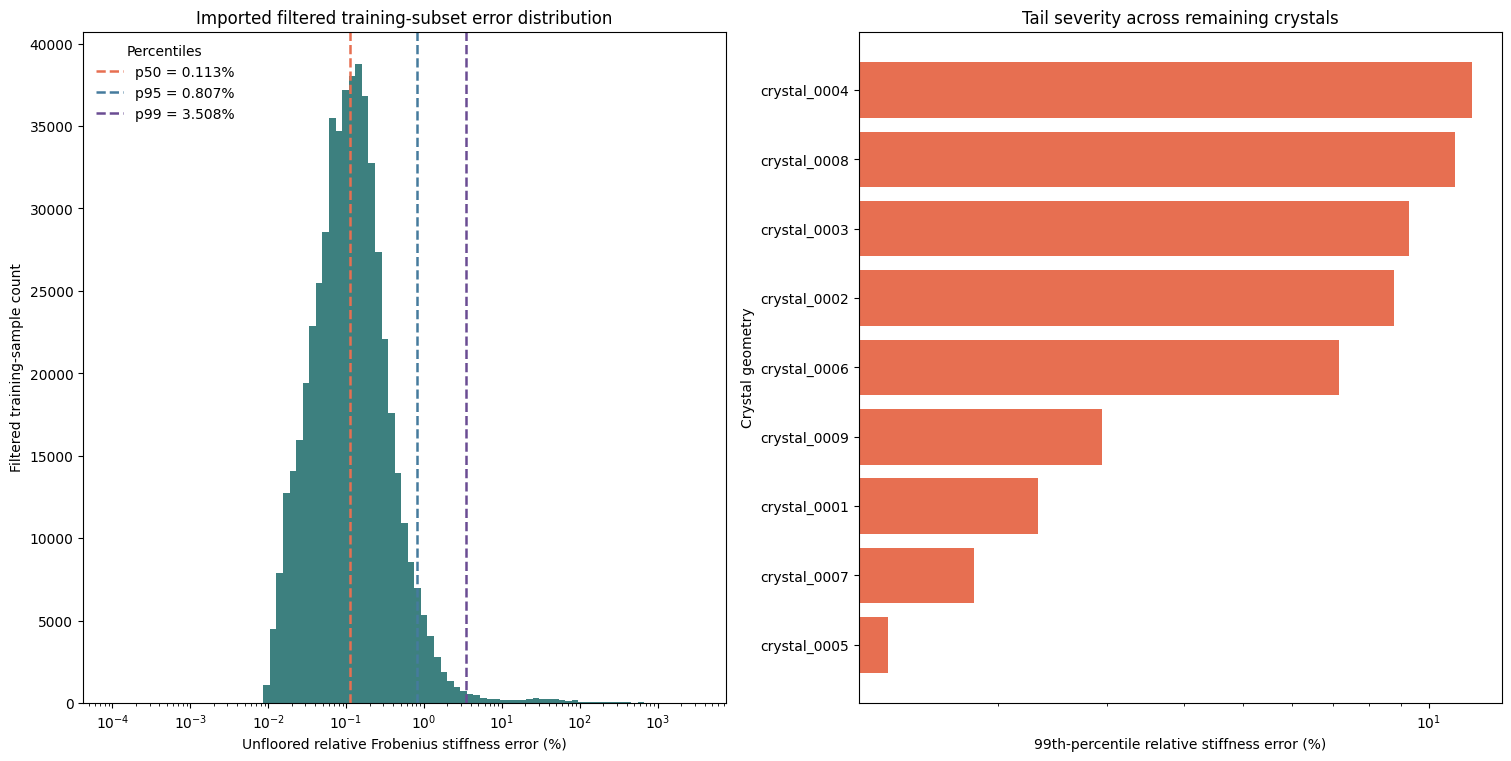

Saved 536,339 per-sample errors to filtered_training_subset_transformer_stiffness_errors.csv.
Median / p95 / p99 / maximum: 0.1128% / 0.8069% / 3.5081% / 11100.8574%.


,dataset_row,geometry_name,flat_index,relative_frobenius_error_percent,absolute_frobenius_error,reference_frobenius_norm,predicted_to_reference_norm_ratio,cut_volume_fraction,inside_corner_count,minimum_normalized_iso_distance
351533,351533,crystal_0003,727457,11100.8574%,1.2681e+00,1.1423e-02,111.5205,0.002357,3,0.013072
298019,298019,crystal_0002,307073,8096.1055%,6.6946e-01,8.2689e-03,81.5471,0.001953,4,0.012758
298020,298020,crystal_0002,307074,8096.1055%,6.6946e-01,8.2689e-03,81.5471,0.001953,4,0.012758
298021,298021,crystal_0002,307075,8096.1055%,6.6946e-01,8.2689e-03,81.5471,0.001953,4,0.012758
298022,298022,crystal_0002,307076,8096.1055%,6.6946e-01,8.2689e-03,81.5471,0.001953,4,0.012758
77188,77188,eggcarton_sphere,484389,4178.9678%,2.7375e-01,6.5508e-03,41.9265,0.001226,4,0.024410
79999,79999,eggcarton_sphere,514310,4026.7976%,2.6379e-01,6.5508e-03,40.3179,0.001226,3,0.024410
321435,321435,crystal_0002,752644,3939.5527%,4.1791e-01,1.0608e-02,39.9892,0.002537,3,0.010631
295144,295144,crystal_0002,246132,3785.7437%,2.2897e-01,6.0482e-03,38.3563,0.001248,2,0.002720
233720,233720,crystal_0000,387252,3659.7800%,4.7128e-01,1.2877e-02,36.9401,0.002873,3,0.000000


In [24]:
TRAINING_ERROR_FILE = OUTPUT_DIR / "filtered_training_subset_transformer_stiffness_errors.csv"
TRAINING_EVALUATION_BATCH_SIZE = 4096

training_error_rows = []
with h5py.File(TRAINING_SUBSET_FILE, "r") as training_h5:
    training_group = training_h5[TRAINING_SUBSET_GROUP]
    for start in range(0, training_subset_rows, TRAINING_EVALUATION_BATCH_SIZE):
        stop = min(start + TRAINING_EVALUATION_BATCH_SIZE, training_subset_rows)
        d_values = np.asarray(training_group["d_values"][start:stop], dtype=np.float32)
        stiffness_ut = np.asarray(training_group["stiffness_ut"][start:stop], dtype=np.float64)
        targets = reconstruct_matrices_from_ut(stiffness_ut).astype(np.float32)

        with torch.inference_mode():
            predicted_unit, log_norm = training_model(torch.from_numpy(d_values).to(training_device))
            predictions = (predicted_unit * torch.exp(log_norm)[:, None, None]).cpu().numpy()

        reference_norm = np.linalg.norm(targets, axis=(1, 2))
        error_norm = np.linalg.norm(predictions - targets, axis=(1, 2))
        training_error_rows.append(pd.DataFrame({
            "dataset_row": np.arange(start, stop, dtype=np.int64),
            "relative_frobenius_error_percent": 100.0 * error_norm / reference_norm,
            "absolute_frobenius_error": error_norm,
            "reference_frobenius_norm": reference_norm,
            "predicted_to_reference_norm_ratio": np.linalg.norm(predictions, axis=(1, 2)) / reference_norm,
            "inside_corner_count": (d_values > 0.5).sum(axis=1),
            "minimum_normalized_iso_distance": np.abs(d_values - 0.5).min(axis=1),
            "geometry_name": np.asarray(training_group["geometry_name"][start:stop]).astype(str),
            "flat_index": np.asarray(training_group["flat_index"][start:stop], dtype=np.int64),
            "cut_volume_fraction": np.asarray(training_group["cut_volume_fraction"][start:stop], dtype=np.float64),
        }))
        if stop == training_subset_rows or stop % (20 * TRAINING_EVALUATION_BATCH_SIZE) == 0:
            print(f"Evaluated {stop:,} / {training_subset_rows:,} training rows ({stop / training_subset_rows:.1%})")

training_errors = pd.concat(training_error_rows, ignore_index=True)
training_errors.to_csv(TRAINING_ERROR_FILE, index=False)
training_worst_cells = training_errors.nlargest(20, "relative_frobenius_error_percent").copy()
training_error_percent = training_errors["relative_frobenius_error_percent"]

figure, axes = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True)
axes[0].hist(training_error_percent, bins=np.logspace(-4, 3.5, 90), color="#287271", alpha=0.9)
axes[0].set_xscale("log")
axes[0].set(
    xlabel="Unfloored relative Frobenius stiffness error (%)",
    ylabel="Filtered training-sample count",
    title="Imported filtered training-subset error distribution",
)
for percentile, color in [(0.50, "#e76f51"), (0.95, "#457b9d"), (0.99, "#6a4c93")]:
    value = training_error_percent.quantile(percentile)
    axes[0].axvline(value, color=color, linestyle="--", linewidth=1.8, label=f"p{int(percentile * 100)} = {value:.3f}%")
axes[0].legend(title="Percentiles", frameon=False, loc="upper left")

geometry_tail = training_errors.groupby("geometry_name", observed=True).agg(
    samples=("dataset_row", "size"),
    median_error_percent=("relative_frobenius_error_percent", "median"),
    p99_error_percent=("relative_frobenius_error_percent", lambda values: values.quantile(0.99)),
    maximum_error_percent=("relative_frobenius_error_percent", "max"),
)
crystal_tail = geometry_tail.loc[
    geometry_tail.index.str.startswith("crystal_") & (geometry_tail.index != "crystal_0000")
].sort_values("p99_error_percent", ascending=False)
axes[1].barh(crystal_tail.index, crystal_tail["p99_error_percent"], color="#e76f51")
axes[1].set_xscale("log")
axes[1].invert_yaxis()
axes[1].set(
    xlabel="99th-percentile relative stiffness error (%)",
    ylabel="Crystal geometry",
    title="Tail severity across remaining crystals",
)
plt.show()

print(f"Saved {len(training_errors):,} per-sample errors to {TRAINING_ERROR_FILE.name}.")
print(f"Median / p95 / p99 / maximum: {training_error_percent.quantile(0.50):.4f}% / {training_error_percent.quantile(0.95):.4f}% / {training_error_percent.quantile(0.99):.4f}% / {training_error_percent.max():.4f}%.")
display(training_worst_cells[[
    "dataset_row", "geometry_name", "flat_index", "relative_frobenius_error_percent",
    "absolute_frobenius_error", "reference_frobenius_norm", "predicted_to_reference_norm_ratio",
    "cut_volume_fraction", "inside_corner_count", "minimum_normalized_iso_distance",
]].style.format({
    "relative_frobenius_error_percent": "{:.4f}%",
    "absolute_frobenius_error": "{:.4e}",
    "reference_frobenius_norm": "{:.4e}",
    "predicted_to_reference_norm_ratio": "{:.4f}",
    "cut_volume_fraction": "{:.6f}",
    "minimum_normalized_iso_distance": "{:.6f}",
}))
training_worst_cells.to_csv(OUTPUT_DIR / "filtered_training_subset_transformer_worst_20_stiffness_errors.csv", index=False)

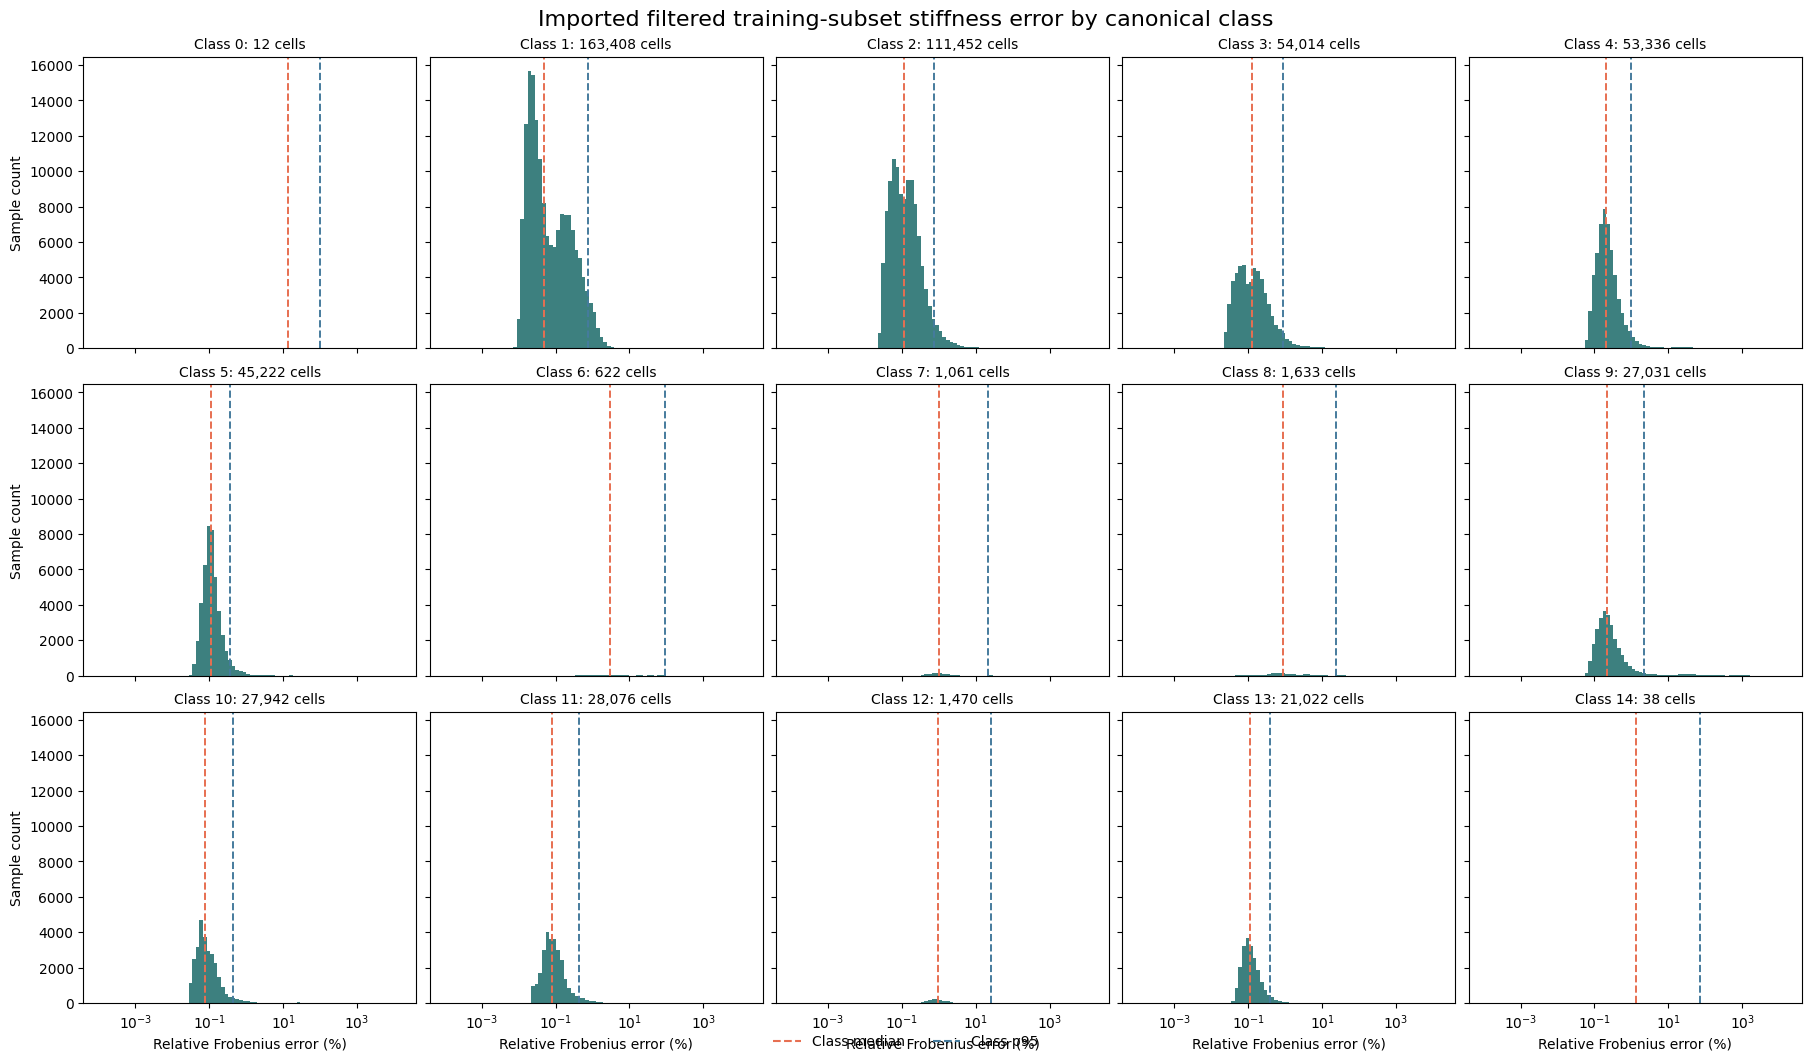

Class labels derived from all 536,339 stored SDF inputs.


,canonical_topology_class,samples,median_error_percent,p95_error_percent,p99_error_percent,maximum_error_percent,sample_fraction
0,0,12,13.3736%,99.3423%,99.7372%,99.8360%,0.00%
1,1,163408,0.0498%,0.7442%,1.4639%,99.9546%,30.47%
2,2,111452,0.1160%,0.7246%,2.5203%,3785.7437%,20.78%
3,3,54014,0.1249%,0.8848%,4.7146%,2809.0876%,10.07%
4,4,53336,0.2066%,0.9735%,15.8295%,4026.7976%,9.94%
5,5,45222,0.1093%,0.3561%,0.9450%,8096.1055%,8.43%
6,6,622,3.0095%,93.8798%,439.8590%,871.8799%,0.12%
7,7,1061,0.9835%,21.8940%,97.8039%,1289.1786%,0.20%
8,8,1633,0.8745%,23.6255%,162.3708%,896.2328%,0.30%
9,9,27031,0.2250%,2.1400%,71.5857%,11100.8574%,5.04%


In [25]:
from clean_simulation.internal_nn_runtime.cutcell_ml.model import compute_vectorized_class_label

TRAINING_CLASS_SUMMARY_FILE = OUTPUT_DIR / "filtered_training_subset_transformer_error_by_class.csv"

class_labels = np.empty(len(training_errors), dtype=np.int64)
with h5py.File(TRAINING_SUBSET_FILE, "r") as training_h5:
    d_dataset = training_h5[TRAINING_SUBSET_GROUP]["d_values"]
    for start in range(0, len(training_errors), TRAINING_EVALUATION_BATCH_SIZE):
        stop = min(start + TRAINING_EVALUATION_BATCH_SIZE, len(training_errors))
        d_values = np.asarray(d_dataset[start:stop], dtype=np.float32)
        class_labels[start:stop] = compute_vectorized_class_label(
            torch.from_numpy(d_values)
        ).cpu().numpy()

training_errors["canonical_topology_class"] = class_labels
class_summary = training_errors.groupby("canonical_topology_class", observed=True).agg(
    samples=("dataset_row", "size"),
    median_error_percent=("relative_frobenius_error_percent", "median"),
    p95_error_percent=("relative_frobenius_error_percent", lambda values: values.quantile(0.95)),
    p99_error_percent=("relative_frobenius_error_percent", lambda values: values.quantile(0.99)),
    maximum_error_percent=("relative_frobenius_error_percent", "max"),
).reset_index()
class_summary["sample_fraction"] = class_summary["samples"] / len(training_errors)
class_summary.to_csv(TRAINING_CLASS_SUMMARY_FILE, index=False)

error_bins = np.logspace(-4, 4.2, 85)
figure, axes = plt.subplots(3, 5, figsize=(18, 10.5), sharex=True, sharey=True, constrained_layout=True)
for class_id, axis in enumerate(axes.flat):
    class_errors = training_errors.loc[
        training_errors["canonical_topology_class"] == class_id,
        "relative_frobenius_error_percent",
    ]
    if class_errors.empty:
        axis.set_visible(False)
        continue
    axis.hist(class_errors, bins=error_bins, color="#287271", alpha=0.9)
    axis.set_xscale("log")
    axis.axvline(class_errors.median(), color="#e76f51", linestyle="--", linewidth=1.4)
    axis.axvline(class_errors.quantile(0.95), color="#457b9d", linestyle="--", linewidth=1.4)
    axis.set_title(f"Class {class_id}: {len(class_errors):,} cells", fontsize=10)

for axis in axes[:, 0]:
    axis.set_ylabel("Sample count")
for axis in axes[-1, :]:
    axis.set_xlabel("Relative Frobenius error (%)")
figure.suptitle("Imported filtered training-subset stiffness error by canonical class", fontsize=16)
figure.legend(
    [plt.Line2D([], [], color="#e76f51", linestyle="--"), plt.Line2D([], [], color="#457b9d", linestyle="--")],
    ["Class median", "Class p95"],
    loc="lower center",
    ncols=2,
    frameon=False,
)
plt.show()

print(f"Class labels derived from all {len(training_errors):,} stored SDF inputs.")
display(class_summary.style.format({
    "sample_fraction": "{:.2%}",
    "median_error_percent": "{:.4f}%",
    "p95_error_percent": "{:.4f}%",
    "p99_error_percent": "{:.4f}%",
    "maximum_error_percent": "{:.4f}%",
}))

In [3]:
import h5py

MATCHED_ERROR_FILE = OUTPUT_DIR / "medium_transformer_0p245952_matched_mc_cell_errors_128cubed.csv"
MATCHED_EXPLANATION_FILE = OUTPUT_DIR / "medium_transformer_0p245952_matched_mc_explanatory_summary_128cubed.csv"
LOCAL_STIFFNESS_YOUNG_MODULUS = 1.0e6


def _load_medium_transformer(device: str):
    from clean_simulation.internal_nn_runtime.cutcell_ml.model import CutCellNetTransformer

    checkpoint = torch.load(MEDIUM_CHECKPOINT, map_location="cpu", weights_only=False)
    model = CutCellNetTransformer(
        embed_dim=256,
        n_heads=8,
        n_layers=8,
        ffn_dim=1024,
        dropout=0.0,
        ordered_sdf_branch=True,
    )
    incompatible = model.load_state_dict(checkpoint["model_state_dict"], strict=False)
    if incompatible.missing_keys or incompatible.unexpected_keys:
        raise RuntimeError(f"Checkpoint/model mismatch: missing={incompatible.missing_keys}, unexpected={incompatible.unexpected_keys}")
    model.set_normalizers(MEDIUM_NORMALIZER_MEAN, MEDIUM_NORMALIZER_STD)
    return model.to(device).eval()


def run_matched_medium_transformer_error_study(*, device: str | None = None) -> pd.DataFrame:
    """Evaluate the medium Transformer under its source-lattice -> MC -> QuESo contract."""
    from clean_simulation.case import build_case_from_stl
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly
    from clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws import (
        lattice_features,
        load_canonical_helpers,
        reconstructed_mesh,
        source_lattice,
    )

    study_device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    helpers = load_canonical_helpers(ROOT / "QuESo" / "out" / "install" / "win")
    helpers["DEVICE"] = study_device
    HexGrid = helpers["HexGrid"]
    Material = helpers["Material"]
    VolumeFactory = helpers["VolumeFactory"]

    with h5py.File(REFERENCE_FILE, "r") as reference_h5:
        bounds = np.asarray(reference_h5.attrs["physical_bounds"], dtype=np.float64)
    grid = HexGrid(
        bounds=(tuple(bounds[0]), tuple(bounds[1])),
        resolution=(WORKING_RESOLUTION,) * 3,
        device="cpu",
    )
    material = Material(E=LOCAL_STIFFNESS_YOUNG_MODULUS, nu=0.3)
    source_volume = VolumeFactory.from_file(SOURCE_STL)

    # This lattice is both the model input source and the sole geometry source for MC.
    lattice = source_lattice(helpers, SOURCE_STL, grid)
    rebuilt_mesh = reconstructed_mesh(helpers, lattice, grid)
    work_dir = OUTPUT_DIR / f"matched_mc_queso_{WORKING_RESOLUTION}cubed"
    work_dir.mkdir(parents=True, exist_ok=True)
    rebuilt_stl = work_dir / f"{SOURCE_STL.stem}_exact_lattice_mc_{WORKING_RESOLUTION}cubed.stl"
    rebuilt_mesh.export(rebuilt_stl)

    case = build_case_from_stl(
        stl_path=rebuilt_stl,
        workspace_root=ROOT,
        work_dir=work_dir,
        queso_python_path=ROOT / "QuESo" / "out" / "install" / "win",
        queso_basis_order=2,
        cut_cells_only=True,
        device="cpu",
        bounds_padding=0.0,
        overrides={
            "grid": {"bounds": bounds.tolist(), "resolution": [WORKING_RESOLUTION] * 3},
            "material": {"E": LOCAL_STIFFNESS_YOUNG_MODULUS, "nu": 0.3},
            "integration": {"poly_order": 1, "gauss_order": 2, "moment_fitting_residual": 1.0e-8},
        },
    )
    queso_matrices, cell_ids_t = StiffnessAssembly.compute_element_matrices_from_queso_points(
        grid=case.grid,
        material=case.material,
        ips=np.asarray(case.ips),
        poly_order=case.poly_order,
        device=study_device,
        element_batch_size=512,
    )
    cell_ids = cell_ids_t.detach().cpu().numpy().astype(np.int64)
    queso_matrices = queso_matrices.detach().cpu().numpy()
    d_values = torch.from_numpy(lattice_features(lattice, cell_ids, grid)).to(dtype=torch.float32)

    model = _load_medium_transformer(study_device)
    predictions = []
    with torch.inference_mode():
        for values in d_values.split(4096):
            predicted_unit, log_norm = model(values.to(study_device))
            predictions.append((predicted_unit * torch.exp(log_norm)[:, None, None]).cpu())
    nn_matrices = torch.cat(predictions).numpy() * (case.material.E * grid.dx)

    error_norm = np.linalg.norm(nn_matrices - queso_matrices, axis=(1, 2))
    reference_norm = np.linalg.norm(queso_matrices, axis=(1, 2))
    relative_error = error_norm / np.maximum(reference_norm, MATRIX_ERROR_EPS)
    raw_lattice_sdf = (d_values.numpy() - 0.5) * (2.0 * np.sqrt(3.0) * grid.dx)
    i = cell_ids // (WORKING_RESOLUTION ** 2)
    j = (cell_ids // WORKING_RESOLUTION) % WORKING_RESOLUTION
    k = cell_ids % WORKING_RESOLUTION
    centers = bounds[0] + (np.column_stack((i, j, k)) + 0.5) * grid.dx

    errors = pd.DataFrame({
        "cell_id": cell_ids,
        "relative_frobenius_error_vs_matched_queso": relative_error,
        "absolute_frobenius_error": error_norm,
        "matched_queso_frobenius_norm": reference_norm,
        "nn_to_queso_norm_ratio": np.linalg.norm(nn_matrices, axis=(1, 2)) / np.maximum(reference_norm, MATRIX_ERROR_EPS),
        "inside_corner_count": (d_values.numpy() > 0.5).sum(axis=1),
        "minimum_absolute_lattice_sdf": np.abs(raw_lattice_sdf).min(axis=1),
        "lattice_sdf_span": np.ptp(raw_lattice_sdf, axis=1),
        "mean_lattice_sdf": raw_lattice_sdf.mean(axis=1),
        "center_x": centers[:, 0],
        "center_y": centers[:, 1],
        "center_z": centers[:, 2],
    })
    errors.to_csv(MATCHED_ERROR_FILE, index=False)

    response = "relative_frobenius_error_vs_matched_queso"
    explanatory = [
        "inside_corner_count", "minimum_absolute_lattice_sdf", "lattice_sdf_span",
        "mean_lattice_sdf", "center_x", "center_y", "center_z", "matched_queso_frobenius_norm",
    ]
    correlations = errors[explanatory + [response]].corr(method="spearman")[response].drop(response)
    summary = pd.DataFrame({"variable": correlations.index, "spearman_rank_correlation": correlations.values})
    summary.to_csv(MATCHED_EXPLANATION_FILE, index=False)

    display(errors[[response, "nn_to_queso_norm_ratio"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
    display(summary.sort_values("spearman_rank_correlation", key=np.abs, ascending=False))
    print(f"Saved matched-contract per-cell errors to {MATCHED_ERROR_FILE}")
    print(f"Saved matched-contract explanatory summary to {MATCHED_EXPLANATION_FILE}")
    return errors


print("Run `run_matched_medium_transformer_error_study()` to evaluate the exact source-lattice and marching-cubes contract.")

Run `run_matched_medium_transformer_error_study()` to evaluate the exact source-lattice and marching-cubes contract.


In [8]:
def _load_medium_transformer(device: str):
    from clean_simulation.internal_nn_runtime.cutcell_ml.model import CutCellNetTransformer

    checkpoint = torch.load(MEDIUM_CHECKPOINT, map_location="cpu", weights_only=False)
    model = CutCellNetTransformer(
        embed_dim=256,
        n_heads=8,
        n_layers=8,
        ffn_dim=1024,
        dropout=0.0,
        ordered_sdf_branch=True,
    )
    incompatible = model.load_state_dict(checkpoint["model_state_dict"], strict=False)
    expected_missing = {"in_mean", "in_std"}
    if set(incompatible.missing_keys) != expected_missing or incompatible.unexpected_keys:
        raise RuntimeError(
            "Checkpoint/model mismatch: "
            f"missing={incompatible.missing_keys}, unexpected={incompatible.unexpected_keys}"
        )
    model.set_normalizers(MEDIUM_NORMALIZER_MEAN, MEDIUM_NORMALIZER_STD)
    return model.to(device).eval()

In [6]:
import importlib

import clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws as exact_lattice_generator

importlib.reload(exact_lattice_generator)

<module 'clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws' from 'C:\\Users\\z0058p1u\\Documents\\code\\clean_simulation\\scripts\\generate_exact_lattice_queso_dataset_aws.py'>

In [9]:
medium_error_study = run_matched_medium_transformer_error_study()

C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices:

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.2473 seconds.
[CASE BUILD] QuESo settings write took 0.0010 seconds.
[QuESo] native grid classification and quadrature generation started.
[QuESo] native grid classification and quadrature generation complete; elapsed=26.3s.
[QuESo] Python integration-point collection started.
[QuESo] Python integration-point collection complete; elapsed=11.7s.
[CASE BUILD] QuESo total took 39.9719 seconds.
[CASE BUILD] QuESo Run() took 26.3119 seconds.
[CASE BUILD] QuESo IP extraction took 11.7244 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 10.1129s.
[CASE BUILD] QuESo weight filtering took 0.0061 seconds.
[CASE BUILD] Total case build time: 40.2227 seconds.


,relative_frobenius_error_vs_matched_queso,nn_to_queso_norm_ratio
count,49908.000000,49908.000000
mean,0.002291,0.999539
std,0.010726,0.009962
min,0.000089,0.433047
50%,0.001010,0.999841
90%,0.004841,1.000543
95%,0.007447,1.001853
99%,0.016460,1.008891
max,1.454430,2.363962


,variable,spearman_rank_correlation
7,matched_queso_frobenius_norm,-0.774811
3,mean_lattice_sdf,-0.769332
0,inside_corner_count,-0.733623
2,lattice_sdf_span,-0.278964
1,minimum_absolute_lattice_sdf,-0.241909
6,center_z,-0.024942
4,center_x,0.013569
5,center_y,-0.005894


Saved matched-contract per-cell errors to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\medium_transformer_0p245952_matched_mc_cell_errors_128cubed.csv
Saved matched-contract explanatory summary to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\medium_transformer_0p245952_matched_mc_explanatory_summary_128cubed.csv


In [4]:
if "medium_error_study" not in globals():
    if not MATCHED_ERROR_FILE.is_file():
        raise FileNotFoundError(
            "Run the medium Transformer study first; no saved matched-contract error CSV is available."
        )
    medium_error_study = pd.read_csv(MATCHED_ERROR_FILE)
    print(f"Loaded cached matched-contract errors from {MATCHED_ERROR_FILE.name}.")

Loaded cached matched-contract errors from medium_transformer_0p245952_matched_mc_cell_errors_128cubed.csv.


## Matched-Contract Error Diagnostics

The plots below use only the valid source-lattice → marching-cubes → QuESo cells. Error is shown on a logarithmic scale because the low-error bulk and rare high-error tail differ by orders of magnitude. The spatial view highlights the worst 20 cells; the conditional summaries group continuous variables by decile and report the median and 95th-percentile error.

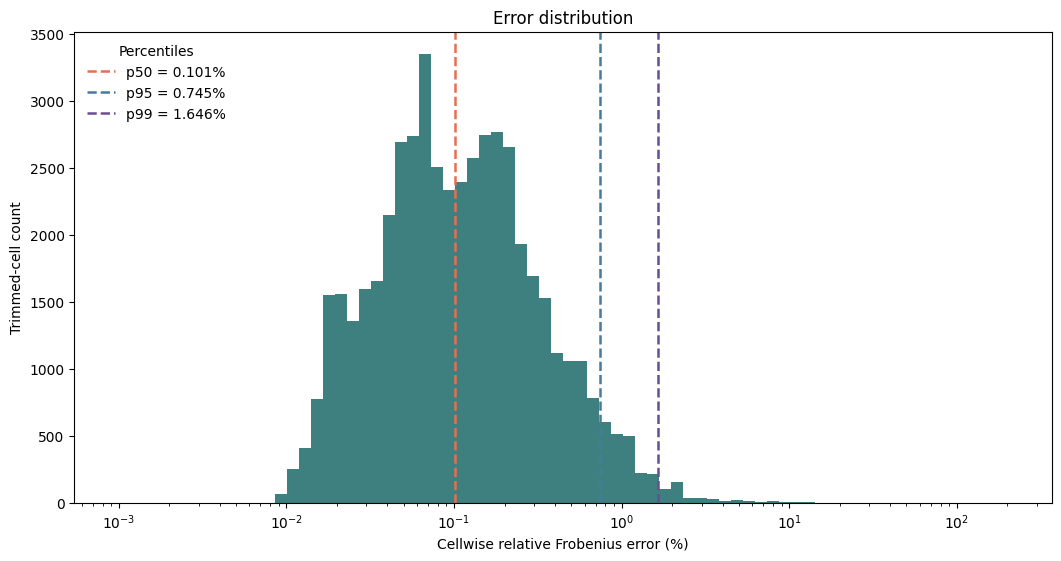

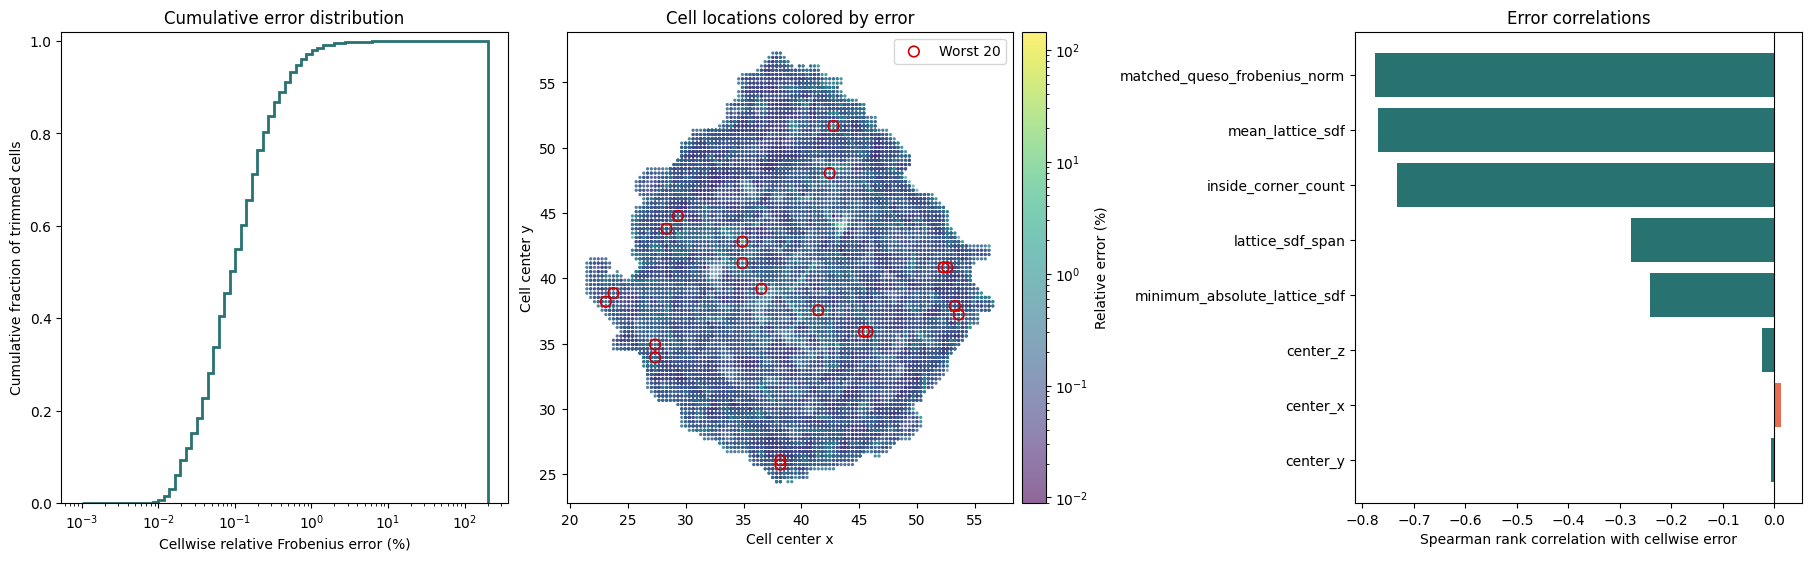

Worst 20 cells are 15.712% to 145.443% relative error.


,cell_id,relative_error_percent,absolute_frobenius_error,matched_queso_frobenius_norm,nn_to_queso_norm_ratio,inside_corner_count,minimum_absolute_lattice_sdf,lattice_sdf_span,mean_lattice_sdf,center_x,center_y,center_z
4086,517163,145.443,6.5812e+04,4.5249e+04,2.36396,2,9.4222e-03,3.9573e-01,-8.4392e-02,28.3359,43.7891,33.2734
2662,464560,74.422,1.0127e+04,1.3608e+04,1.72532,2,0.0000e+00,3.4188e-01,-1.0459e-01,27.3516,34.9297,34.9141
22234,1001659,61.449,8.9283e+04,1.4530e+05,0.43305,2,3.6084e-02,3.4616e-01,-7.0126e-02,38.1797,25.7422,38.5234
48966,1776209,59.094,1.8857e+04,3.1911e+04,1.57047,2,0.0000e+00,3.2470e-01,-1.0772e-01,53.6016,37.2266,45.7422
356,285885,58.404,6.3091e+04,1.0802e+05,0.45318,2,1.8042e-02,3.2980e-01,-8.6906e-02,23.7422,38.8672,39.1797
202,252861,49.408,4.8587e+04,9.8338e+04,0.54394,2,1.8042e-02,4.0026e-01,-1.0314e-01,23.0859,38.2109,39.1797
5904,566741,46.188,4.2698e+04,9.2445e+04,0.57780,2,1.5625e-02,4.1062e-01,-1.1737e-01,29.3203,44.7734,47.0547
15925,844518,29.737,7.2141e+03,2.4259e+04,1.28904,2,0.0000e+00,3.7125e-01,-1.5360e-01,34.8984,42.8047,52.6328
47634,1712084,29.679,1.1645e+04,3.9235e+04,1.27610,2,8.1190e-02,3.8607e-01,-9.5619e-02,52.2891,40.8359,46.7266
48154,1728467,28.924,1.1348e+04,3.9235e+04,1.26862,2,8.1190e-02,3.7889e-01,-9.4722e-02,52.6172,40.8359,46.3984


,variable,group,cells,median,p95,mean
0,inside_corner_count,1,9595,0.2248%,1.1533%,0.3752%
1,inside_corner_count,2,6929,0.2099%,1.2380%,0.4735%
2,inside_corner_count,3,2252,0.2900%,0.9909%,0.4807%
3,inside_corner_count,4,12681,0.0856%,0.3709%,0.1420%
4,inside_corner_count,5,2409,0.2090%,0.8194%,0.3486%
5,inside_corner_count,6,6145,0.0580%,0.1412%,0.0878%
6,inside_corner_count,7,9897,0.0240%,0.0637%,0.0294%
7,mean_lattice_sdf,"(-0.28, -0.198]",4991,0.4044%,1.4355%,0.5398%
8,mean_lattice_sdf,"(-0.198, -0.153]",4991,0.2248%,0.8994%,0.3428%
9,mean_lattice_sdf,"(-0.153, -0.101]",4999,0.1939%,0.8562%,0.3847%


In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ERROR_COLUMN = "relative_frobenius_error_vs_matched_queso"
EXPLANATORY_COLUMNS = [
    "inside_corner_count",
    "minimum_absolute_lattice_sdf",
    "lattice_sdf_span",
    "mean_lattice_sdf",
    "center_x",
    "center_y",
    "center_z",
    "matched_queso_frobenius_norm",
]

error_diagnostics = medium_error_study.copy()
error_diagnostics["relative_error_percent"] = 100.0 * error_diagnostics[ERROR_COLUMN]
worst_cells = error_diagnostics.nlargest(20, ERROR_COLUMN).copy()
correlations = (
    error_diagnostics[EXPLANATORY_COLUMNS + [ERROR_COLUMN]]
    .corr(method="spearman")[ERROR_COLUMN]
    .drop(ERROR_COLUMN)
    .sort_values(key=np.abs, ascending=False)
)

fig_distribution, distribution_axis = plt.subplots(figsize=(10.5, 5.5), constrained_layout=True)
distribution_axis.hist(
    error_diagnostics["relative_error_percent"],
    bins=np.logspace(-3, 2.3, 75),
    color="#287271",
    alpha=0.9,
)
distribution_axis.set_xscale("log")
distribution_axis.set(
    xlabel="Cellwise relative Frobenius error (%)",
    ylabel="Trimmed-cell count",
    title="Error distribution",
)
for percentile, color in [(0.50, "#e76f51"), (0.95, "#457b9d"), (0.99, "#6a4c93")]:
    value = error_diagnostics["relative_error_percent"].quantile(percentile)
    distribution_axis.axvline(
        value,
        color=color,
        linestyle="--",
        linewidth=1.8,
        label=f"p{int(percentile * 100)} = {value:.3f}%",
    )
distribution_axis.legend(title="Percentiles", frameon=False, loc="upper left")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

axes[0].hist(error_diagnostics["relative_error_percent"], bins=np.logspace(-3, 2.3, 75), density=True, cumulative=True, histtype="step", linewidth=2.0, color="#287271")
axes[0].set_xscale("log")
axes[0].set_xlabel("Cellwise relative Frobenius error (%)")
axes[0].set_ylabel("Cumulative fraction of trimmed cells")
axes[0].set_ylim(0.0, 1.02)
axes[0].set_title("Cumulative error distribution")

scatter = axes[1].scatter(
    error_diagnostics["center_x"],
    error_diagnostics["center_y"],
    c=error_diagnostics["relative_error_percent"],
    s=5,
    cmap="viridis",
    norm=LogNorm(vmin=error_diagnostics["relative_error_percent"].min(), vmax=error_diagnostics["relative_error_percent"].max()),
    alpha=0.6,
    linewidths=0,
)
axes[1].scatter(worst_cells["center_x"], worst_cells["center_y"], facecolors="none", edgecolors="#d00000", s=58, linewidths=1.2, label="Worst 20")
axes[1].set_xlabel("Cell center x")
axes[1].set_ylabel("Cell center y")
axes[1].set_title("Cell locations colored by error")
axes[1].legend(loc="upper right")
fig.colorbar(scatter, ax=axes[1], label="Relative error (%)", pad=0.02)

correlation_colors = np.where(correlations.values < 0.0, "#287271", "#e76f51")
axes[2].barh(correlations.index, correlations.values, color=correlation_colors)
axes[2].axvline(0.0, color="black", linewidth=0.8)
axes[2].set_xlabel("Spearman rank correlation with cellwise error")
axes[2].set_title("Error correlations")
axes[2].invert_yaxis()

plt.show()

conditional_summaries = []
for variable in ["inside_corner_count", "mean_lattice_sdf", "matched_queso_frobenius_norm", "lattice_sdf_span", "minimum_absolute_lattice_sdf"]:
    if variable == "inside_corner_count":
        groups = error_diagnostics[variable].astype(int)
    else:
        groups = pd.qcut(error_diagnostics[variable], q=10, duplicates="drop")
    grouped = error_diagnostics.groupby(groups, observed=True)[ERROR_COLUMN].agg(
        cells="size",
        median="median",
        p95=lambda values: values.quantile(0.95),
        mean="mean",
    ).reset_index(names="group")
    grouped.insert(0, "variable", variable)
    grouped[["median", "p95", "mean"]] *= 100.0
    conditional_summaries.append(grouped)

conditional_error_summary = pd.concat(conditional_summaries, ignore_index=True)
worst_cell_table = worst_cells[[
    "cell_id", "relative_error_percent", "absolute_frobenius_error", "matched_queso_frobenius_norm",
    "nn_to_queso_norm_ratio", "inside_corner_count", "minimum_absolute_lattice_sdf", "lattice_sdf_span",
    "mean_lattice_sdf", "center_x", "center_y", "center_z",
]].sort_values("relative_error_percent", ascending=False)

print(f"Worst 20 cells are {worst_cells[ERROR_COLUMN].min():.3%} to {worst_cells[ERROR_COLUMN].max():.3%} relative error.")
display(worst_cell_table.style.format({
    "relative_error_percent": "{:.3f}",
    "absolute_frobenius_error": "{:.4e}",
    "matched_queso_frobenius_norm": "{:.4e}",
    "nn_to_queso_norm_ratio": "{:.5f}",
    "minimum_absolute_lattice_sdf": "{:.4e}",
    "lattice_sdf_span": "{:.4e}",
    "mean_lattice_sdf": "{:.4e}",
    "center_x": "{:.4f}",
    "center_y": "{:.4f}",
    "center_z": "{:.4f}",
}))
display(conditional_error_summary.style.format({"median": "{:.4f}%", "p95": "{:.4f}%", "mean": "{:.4f}%"}))

## Crystal Worst-Cell and Node-Exposure Study

This cached analysis explains the high-error tail of the matched source-lattice to marching-cubes to QuESo comparison. Node exposure means a crystal grid node incident to a high-error trimmed cell; it is structural attribution, not an independent displacement-error measurement.

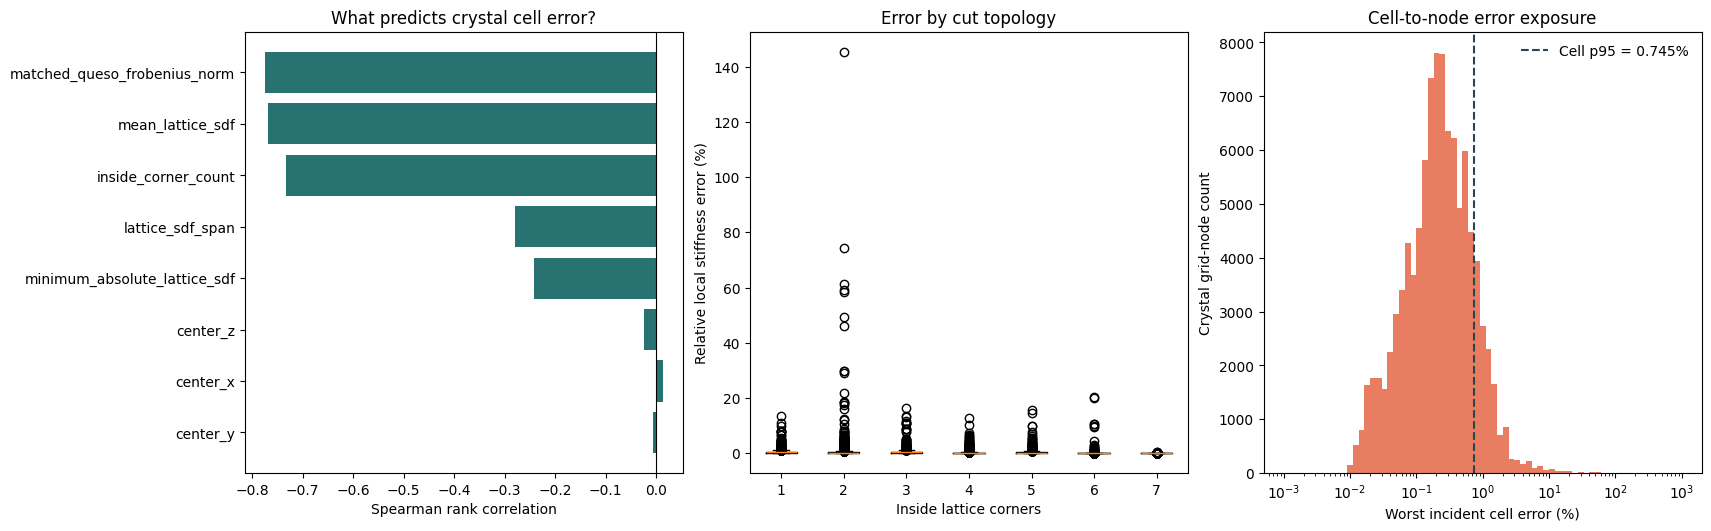

Crystal trimmed cells: 49,908
Cell-error median / p95 / p99 / maximum: 0.1010% / 0.7447% / 1.6460% / 145.4430%
Crystal nodes incident to trimmed cells: 99,695
Nodes incident to a top-5% cell: 13,539 (13.58%)


,spearman_rank_correlation
matched_queso_frobenius_norm,-0.774811
mean_lattice_sdf,-0.769324
inside_corner_count,-0.733623
lattice_sdf_span,-0.278927
minimum_absolute_lattice_sdf,-0.241909
center_z,-0.024942
center_x,0.013569
center_y,-0.005894


,inside_corner_count,cells,median_error_percent,p95_error_percent,top_5_percent_cells
0,1,9595,0.2248,1.1533,1259
1,2,6929,0.2099,1.2380,620
2,3,2252,0.2900,0.9909,237
3,4,12681,0.0856,0.3709,198
4,5,2409,0.2090,0.8194,148
5,6,6145,0.0580,0.1412,34
6,7,9897,0.0240,0.0637,0


,cell_id,relative_error_percent,inside_corner_count,minimum_absolute_lattice_sdf,lattice_sdf_span,mean_lattice_sdf,matched_queso_frobenius_norm
4086,517163,145.4430,2,0.00942,0.39573,-0.08439,4.5249e+04
2662,464560,74.4215,2,0.00000,0.34188,-0.10459,1.3608e+04
22234,1001659,61.4485,2,0.03608,0.34616,-0.07013,1.4530e+05
48966,1776209,59.0942,2,0.00000,0.32470,-0.10772,3.1911e+04
356,285885,58.4040,2,0.01804,0.32980,-0.08691,1.0802e+05
202,252861,49.4081,2,0.01804,0.40026,-0.10314,9.8338e+04
5904,566741,46.1880,2,0.01563,0.41062,-0.11737,9.2445e+04
15925,844518,29.7373,2,0.00000,0.37125,-0.15360,2.4259e+04
47634,1712084,29.6790,2,0.08119,0.38607,-0.09562,3.9235e+04
48154,1728467,28.9239,2,0.08119,0.37889,-0.09472,3.9235e+04


In [7]:
from IPython.display import display

CRYSTAL_ERROR_COLUMN = "relative_frobenius_error_vs_matched_queso"
CRYSTAL_RESOLUTION = WORKING_RESOLUTION
CRYSTAL_TOP_QUANTILE = 0.95

crystal_errors = medium_error_study.copy()
crystal_errors["relative_error_percent"] = 100.0 * crystal_errors[CRYSTAL_ERROR_COLUMN]
crystal_errors["error_percentile"] = crystal_errors[CRYSTAL_ERROR_COLUMN].rank(pct=True, method="max")
crystal_worst_cells = crystal_errors.nlargest(20, CRYSTAL_ERROR_COLUMN).copy()
crystal_correlations = (
    crystal_errors[EXPLANATORY_COLUMNS + [CRYSTAL_ERROR_COLUMN]]
    .corr(method="spearman")[CRYSTAL_ERROR_COLUMN]
    .drop(CRYSTAL_ERROR_COLUMN)
    .sort_values(key=np.abs, ascending=False)
)
crystal_topology_summary = crystal_errors.groupby("inside_corner_count").agg(
    cells=("cell_id", "size"),
    median_error_percent=("relative_error_percent", "median"),
    p95_error_percent=("relative_error_percent", lambda values: values.quantile(0.95)),
    top_5_percent_cells=("error_percentile", lambda values: (values >= CRYSTAL_TOP_QUANTILE).sum()),
).reset_index()


def crystal_cell_nodes(cell_ids):
    node_side = CRYSTAL_RESOLUTION + 1
    i = cell_ids // (CRYSTAL_RESOLUTION ** 2)
    j = (cell_ids // CRYSTAL_RESOLUTION) % CRYSTAL_RESOLUTION
    k = cell_ids % CRYSTAL_RESOLUTION
    base = (i * node_side + j) * node_side + k
    offsets = np.array((
        0, node_side ** 2, node_side ** 2 + node_side, node_side,
        1, node_side ** 2 + 1, node_side ** 2 + node_side + 1, node_side + 1,
    ))
    return base[:, None] + offsets


crystal_cell_ids = crystal_errors["cell_id"].to_numpy(dtype=np.int64)
crystal_cell_error = crystal_errors["relative_error_percent"].to_numpy()
crystal_nodes_by_cell = crystal_cell_nodes(crystal_cell_ids)
crystal_node_count = (CRYSTAL_RESOLUTION + 1) ** 3
crystal_incident_count = np.zeros(crystal_node_count, dtype=np.int64)
crystal_worst_incident_error = np.zeros(crystal_node_count, dtype=np.float64)
np.add.at(crystal_incident_count, crystal_nodes_by_cell.ravel(), 1)
np.maximum.at(
    crystal_worst_incident_error,
    crystal_nodes_by_cell.ravel(),
    np.repeat(crystal_cell_error, 8),
)
crystal_p95 = crystal_errors["relative_error_percent"].quantile(CRYSTAL_TOP_QUANTILE)
crystal_top_cells = crystal_cell_error >= crystal_p95
crystal_top_incidence = np.zeros(crystal_node_count, dtype=np.int64)
np.add.at(crystal_top_incidence, crystal_nodes_by_cell[crystal_top_cells].ravel(), 1)
crystal_exposed = crystal_incident_count > 0
crystal_node_exposure = pd.DataFrame({
    "node_id": np.flatnonzero(crystal_exposed),
    "incident_trimmed_cells": crystal_incident_count[crystal_exposed],
    "incident_top_5_percent_cells": crystal_top_incidence[crystal_exposed],
    "worst_incident_cell_error_percent": crystal_worst_incident_error[crystal_exposed],
})
crystal_node_exposure["incident_to_top_5_percent_cell"] = (
    crystal_node_exposure["incident_top_5_percent_cells"] > 0
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
axes[0].barh(crystal_correlations.index, crystal_correlations.values, color="#287271")
axes[0].axvline(0.0, color="black", linewidth=0.8)
axes[0].invert_yaxis()
axes[0].set(xlabel="Spearman rank correlation", title="What predicts crystal cell error?")
axes[1].boxplot(
    [crystal_errors.loc[crystal_errors.inside_corner_count == count, "relative_error_percent"] for count in crystal_topology_summary.inside_corner_count],
    tick_labels=crystal_topology_summary.inside_corner_count,
)
axes[1].set(xlabel="Inside lattice corners", ylabel="Relative local stiffness error (%)", title="Error by cut topology")
axes[2].hist(
    crystal_node_exposure["worst_incident_cell_error_percent"],
    bins=np.logspace(-3, 3, 70), color="#e76f51", alpha=0.9,
)
axes[2].axvline(crystal_p95, color="#264653", linestyle="--", label=f"Cell p95 = {crystal_p95:.3f}%")
axes[2].set_xscale("log")
axes[2].set(xlabel="Worst incident cell error (%)", ylabel="Crystal grid-node count", title="Cell-to-node error exposure")
axes[2].legend(frameon=False)
plt.show()

print(f"Crystal trimmed cells: {len(crystal_errors):,}")
print(f"Cell-error median / p95 / p99 / maximum: {crystal_errors.relative_error_percent.quantile(0.50):.4f}% / {crystal_errors.relative_error_percent.quantile(0.95):.4f}% / {crystal_errors.relative_error_percent.quantile(0.99):.4f}% / {crystal_errors.relative_error_percent.max():.4f}%")
print(f"Crystal nodes incident to trimmed cells: {len(crystal_node_exposure):,}")
print(f"Nodes incident to a top-5% cell: {crystal_node_exposure.incident_to_top_5_percent_cell.sum():,} ({crystal_node_exposure.incident_to_top_5_percent_cell.mean():.2%})")
display(crystal_correlations.rename("spearman_rank_correlation").to_frame())
display(crystal_topology_summary.style.format({"median_error_percent": "{:.4f}", "p95_error_percent": "{:.4f}"}))
display(crystal_worst_cells[["cell_id", "relative_error_percent", "inside_corner_count", "minimum_absolute_lattice_sdf", "lattice_sdf_span", "mean_lattice_sdf", "matched_queso_frobenius_norm"]].style.format({"relative_error_percent": "{:.4f}", "minimum_absolute_lattice_sdf": "{:.5f}", "lattice_sdf_span": "{:.5f}", "mean_lattice_sdf": "{:.5f}", "matched_queso_frobenius_norm": "{:.4e}"}))

crystal_worst_cells.to_csv(OUTPUT_DIR / "crystal_worst_20_cells_128cubed.csv", index=False)
crystal_node_exposure.to_csv(OUTPUT_DIR / "crystal_cell_to_node_exposure_128cubed.csv", index=False)
crystal_topology_summary.to_csv(OUTPUT_DIR / "crystal_error_by_inside_corner_count_128cubed.csv", index=False)
crystal_correlations.rename("spearman_rank_correlation").to_csv(OUTPUT_DIR / "crystal_worst_cell_spearman_128cubed.csv")

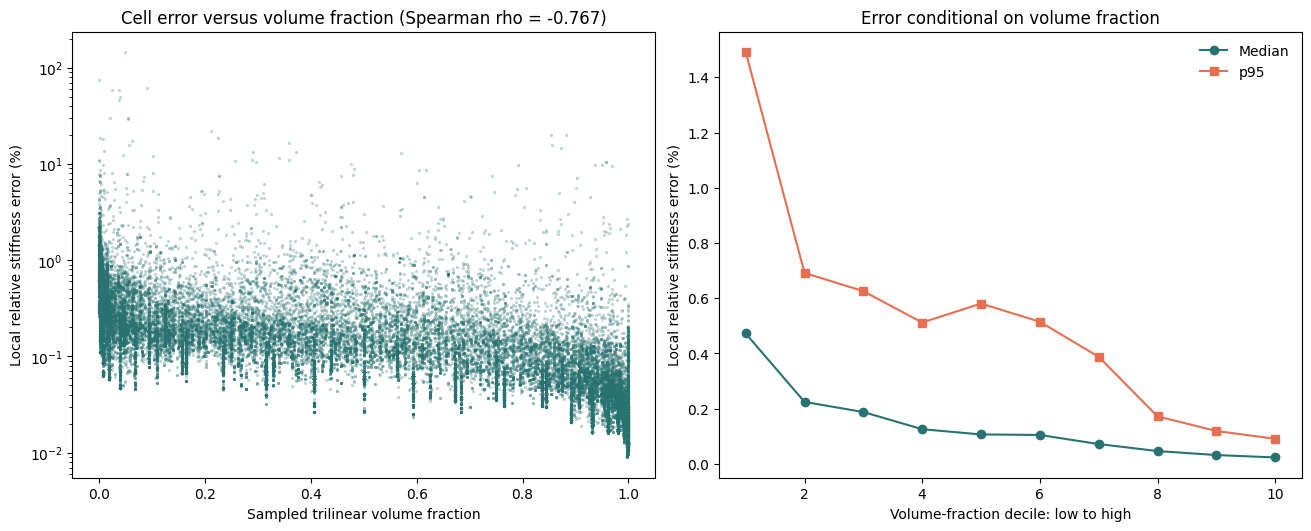

Volume-fraction correlation with local error: Spearman rho = -0.7673; Pearson r = -0.1419
Sampling resolution: 8^3 midpoint samples per matched cell.


,volume_fraction_bin,cells,median,p95,mean
0,"(-0.001, 0.00781]",5588,0.4724%,1.4917%,0.6370%
1,"(0.00781, 0.0391]",4636,0.2248%,0.6918%,0.3559%
2,"(0.0391, 0.139]",4770,0.1880%,0.6257%,0.3338%
3,"(0.139, 0.316]",6075,0.1260%,0.5121%,0.2109%
4,"(0.316, 0.447]",3894,0.1069%,0.5808%,0.1991%
5,"(0.447, 0.645]",4989,0.1050%,0.5149%,0.1898%
6,"(0.645, 0.832]",4986,0.0721%,0.3880%,0.1389%
7,"(0.832, 0.932]",5671,0.0468%,0.1724%,0.0869%
8,"(0.932, 0.98]",4635,0.0323%,0.1194%,0.0606%
9,"(0.98, 1.0]",4664,0.0236%,0.0912%,0.0352%


In [9]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws import (
    load_canonical_helpers,
    source_lattice,
)

VOLUME_FRACTION_SAMPLES_PER_AXIS = 8
helpers = load_canonical_helpers(ROOT / "QuESo" / "out" / "install" / "win")
with h5py.File(REFERENCE_FILE, "r") as reference_h5:
    crystal_bounds = np.asarray(reference_h5.attrs["physical_bounds"], dtype=np.float64)
crystal_grid = helpers["HexGrid"](
    bounds=(tuple(crystal_bounds[0]), tuple(crystal_bounds[1])),
    resolution=(CRYSTAL_RESOLUTION,) * 3,
    device="cpu",
)
crystal_lattice = source_lattice(helpers, SOURCE_STL, crystal_grid)

# The matched model and marching-cubes geometry are driven by this lattice.
# Midpoint sampling estimates each cell's trilinear-SDF occupied volume fraction.
subcell = (np.arange(VOLUME_FRACTION_SAMPLES_PER_AXIS) + 0.5) / VOLUME_FRACTION_SAMPLES_PER_AXIS
sx, sy, sz = np.meshgrid(subcell, subcell, subcell, indexing="ij")
weights = np.column_stack((
    (1 - sx.ravel()) * (1 - sy.ravel()) * (1 - sz.ravel()),
    sx.ravel() * (1 - sy.ravel()) * (1 - sz.ravel()),
    sx.ravel() * sy.ravel() * (1 - sz.ravel()),
    (1 - sx.ravel()) * sy.ravel() * (1 - sz.ravel()),
    (1 - sx.ravel()) * (1 - sy.ravel()) * sz.ravel(),
    sx.ravel() * (1 - sy.ravel()) * sz.ravel(),
    sx.ravel() * sy.ravel() * sz.ravel(),
    (1 - sx.ravel()) * sy.ravel() * sz.ravel(),
))
cell_ids = crystal_errors["cell_id"].to_numpy(dtype=np.int64)
i = cell_ids // (CRYSTAL_RESOLUTION ** 2)
j = (cell_ids // CRYSTAL_RESOLUTION) % CRYSTAL_RESOLUTION
k = cell_ids % CRYSTAL_RESOLUTION
corner_sdf = np.column_stack((
    crystal_lattice[i, j, k], crystal_lattice[i + 1, j, k],
    crystal_lattice[i + 1, j + 1, k], crystal_lattice[i, j + 1, k],
    crystal_lattice[i, j, k + 1], crystal_lattice[i + 1, j, k + 1],
    crystal_lattice[i + 1, j + 1, k + 1], crystal_lattice[i, j + 1, k + 1],
))
crystal_volume_fraction = np.empty(len(cell_ids), dtype=np.float64)
for start in range(0, len(cell_ids), 2048):
    stop = min(start + 2048, len(cell_ids))
    sampled_sdf = corner_sdf[start:stop] @ weights.T
    crystal_volume_fraction[start:stop] = (sampled_sdf >= 0.0).mean(axis=1)

crystal_errors["sampled_trilinear_volume_fraction"] = crystal_volume_fraction
volume_spearman = crystal_errors["relative_error_percent"].corr(
    crystal_errors["sampled_trilinear_volume_fraction"], method="spearman"
)
volume_pearson = crystal_errors["relative_error_percent"].corr(
    crystal_errors["sampled_trilinear_volume_fraction"], method="pearson"
)
volume_summary = crystal_errors.groupby(
    pd.qcut(crystal_errors["sampled_trilinear_volume_fraction"], q=10, duplicates="drop"),
    observed=True,
)["relative_error_percent"].agg(
    cells="size", median="median", p95=lambda values: values.quantile(0.95), mean="mean"
).reset_index(names="volume_fraction_bin")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
axes[0].scatter(
    crystal_errors["sampled_trilinear_volume_fraction"],
    crystal_errors["relative_error_percent"],
    s=5, alpha=0.3, color="#287271", linewidths=0,
)
axes[0].set_yscale("log")
axes[0].set(
    xlabel="Sampled trilinear volume fraction",
    ylabel="Local relative stiffness error (%)",
    title=f"Cell error versus volume fraction (Spearman rho = {volume_spearman:.3f})",
)
axes[1].plot(volume_summary.index + 1, volume_summary["median"], marker="o", color="#287271", label="Median")
axes[1].plot(volume_summary.index + 1, volume_summary["p95"], marker="s", color="#e76f51", label="p95")
axes[1].set(
    xlabel="Volume-fraction decile: low to high",
    ylabel="Local relative stiffness error (%)",
    title="Error conditional on volume fraction",
)
axes[1].legend(frameon=False)
plt.show()

print(f"Volume-fraction correlation with local error: Spearman rho = {volume_spearman:.4f}; Pearson r = {volume_pearson:.4f}")
print(f"Sampling resolution: {VOLUME_FRACTION_SAMPLES_PER_AXIS}^3 midpoint samples per matched cell.")
display(volume_summary.style.format({"median": "{:.4f}%", "p95": "{:.4f}%", "mean": "{:.4f}%"}))
crystal_errors[["cell_id", "relative_error_percent", "sampled_trilinear_volume_fraction"]].to_csv(
    OUTPUT_DIR / "crystal_error_vs_sampled_volume_fraction_128cubed.csv", index=False
)

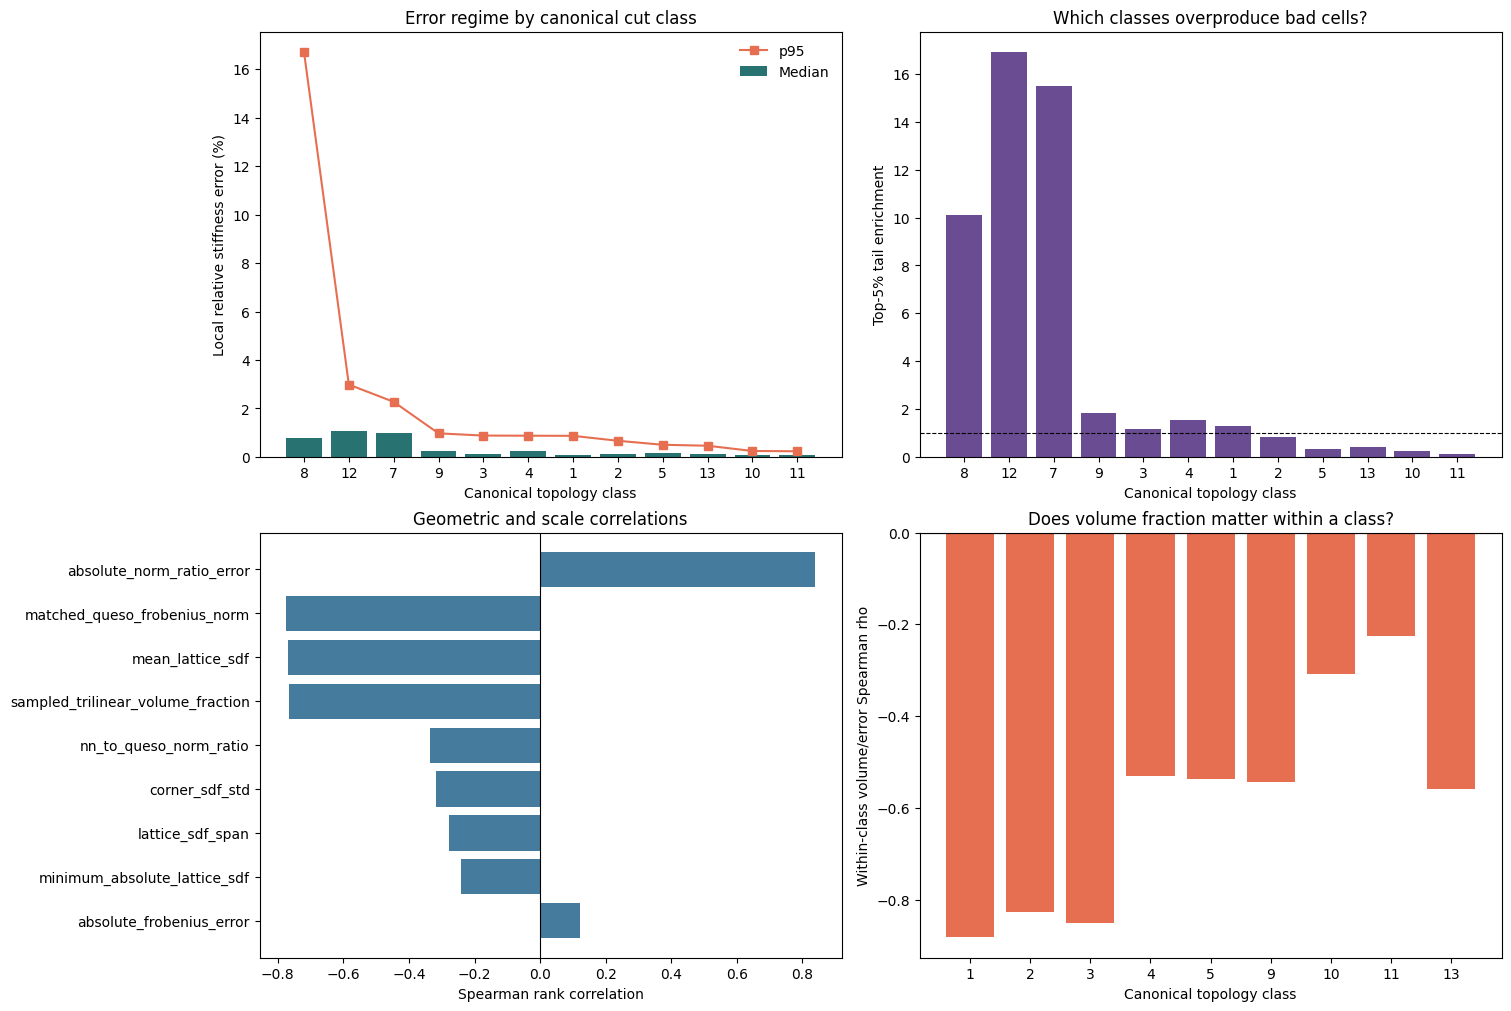

Canonical class study uses the Transformer classifier's exact 15-class label.
Tail enrichment > 1 means that class appears in the worst 5% more often than expected from its population share.


,canonical_topology_class,cells,median_error_percent,p95_error_percent,p99_error_percent,mean_volume_fraction,top_5_percent_cells,top_5_percent_rate,tail_enrichment
6,8,93,0.7747%,16.7185%,54.1284%,0.5071,47,50.54%,10.11x
10,12,26,1.0755%,2.9844%,6.3267%,0.3661,22,84.62%,16.92x
5,7,31,0.9920%,2.2731%,3.4402%,0.4228,24,77.42%,15.48x
7,9,1638,0.2433%,0.9720%,2.7288%,0.5164,149,9.10%,1.82x
2,3,4647,0.1176%,0.8800%,2.1870%,0.4527,266,5.72%,1.14x
3,4,3023,0.2485%,0.8745%,3.0962%,0.4966,236,7.81%,1.56x
0,1,19492,0.0648%,0.8688%,1.4570%,0.5029,1259,6.46%,1.29x
1,2,8334,0.1126%,0.6649%,2.1555%,0.4515,341,4.09%,0.82x
4,5,2595,0.1512%,0.5005%,0.9643%,0.4928,41,1.58%,0.32x
11,13,1359,0.1316%,0.4606%,0.9760%,0.5541,27,1.99%,0.40x


,canonical_topology_class,cells,volume_error_spearman
0,1,19492.000000,-0.8820
1,2,8334.000000,-0.8257
2,3,4647.000000,-0.8501
3,4,3023.000000,-0.5302
4,5,2595.000000,-0.5365
5,7,31.000000,-0.2359
6,8,93.000000,-0.7321
7,9,1638.000000,-0.5431
8,10,4048.000000,-0.3091
9,11,4622.000000,-0.2257


,spearman_rank_correlation
absolute_norm_ratio_error,0.839204
matched_queso_frobenius_norm,-0.774811
mean_lattice_sdf,-0.769324
sampled_trilinear_volume_fraction,-0.767322
nn_to_queso_norm_ratio,-0.337277
corner_sdf_std,-0.317949
lattice_sdf_span,-0.278927
minimum_absolute_lattice_sdf,-0.241909
absolute_frobenius_error,0.122901


In [11]:
import torch

from clean_simulation.internal_nn_runtime.cutcell_ml.model import compute_vectorized_class_label
from clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws import lattice_features

crystal_model_inputs = lattice_features(crystal_lattice, cell_ids, crystal_grid)
crystal_errors["canonical_topology_class"] = (
    compute_vectorized_class_label(torch.from_numpy(crystal_model_inputs).float())
    .cpu().numpy()
)
crystal_errors["absolute_norm_ratio_error"] = np.abs(
    crystal_errors["nn_to_queso_norm_ratio"] - 1.0
)
crystal_errors["corner_sdf_std"] = corner_sdf.std(axis=1)

class_summary = crystal_errors.groupby("canonical_topology_class").agg(
    cells=("cell_id", "size"),
    median_error_percent=("relative_error_percent", "median"),
    p95_error_percent=("relative_error_percent", lambda values: values.quantile(0.95)),
    p99_error_percent=("relative_error_percent", lambda values: values.quantile(0.99)),
    mean_volume_fraction=("sampled_trilinear_volume_fraction", "mean"),
    top_5_percent_cells=("error_percentile", lambda values: (values >= CRYSTAL_TOP_QUANTILE).sum()),
).reset_index()
class_summary["top_5_percent_rate"] = class_summary["top_5_percent_cells"] / class_summary["cells"]
class_summary["tail_enrichment"] = class_summary["top_5_percent_rate"] / (1.0 - CRYSTAL_TOP_QUANTILE)
class_summary = class_summary.sort_values("p95_error_percent", ascending=False)

within_class_volume = (
    crystal_errors.groupby("canonical_topology_class", group_keys=False)
    .apply(lambda group: pd.Series({
        "cells": len(group),
        "volume_error_spearman": group["sampled_trilinear_volume_fraction"].corr(group["relative_error_percent"], method="spearman"),
    }), include_groups=False)
    .reset_index()
)
metric_correlations = crystal_errors[[
    "relative_error_percent",
    "absolute_frobenius_error",
    "matched_queso_frobenius_norm",
    "nn_to_queso_norm_ratio",
    "absolute_norm_ratio_error",
    "sampled_trilinear_volume_fraction",
    "corner_sdf_std",
    "minimum_absolute_lattice_sdf",
    "lattice_sdf_span",
    "mean_lattice_sdf",
]].corr(method="spearman")["relative_error_percent"].drop("relative_error_percent").sort_values(key=np.abs, ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
axes[0, 0].bar(class_summary["canonical_topology_class"].astype(str), class_summary["median_error_percent"], color="#287271", label="Median")
axes[0, 0].plot(class_summary["canonical_topology_class"].astype(str), class_summary["p95_error_percent"], "s-", color="#e76f51", label="p95")
axes[0, 0].set(xlabel="Canonical topology class", ylabel="Local relative stiffness error (%)", title="Error regime by canonical cut class")
axes[0, 0].legend(frameon=False)
axes[0, 1].bar(class_summary["canonical_topology_class"].astype(str), class_summary["tail_enrichment"], color="#6a4c93")
axes[0, 1].axhline(1.0, color="black", linewidth=0.8, linestyle="--")
axes[0, 1].set(xlabel="Canonical topology class", ylabel="Top-5% tail enrichment", title="Which classes overproduce bad cells?")
axes[1, 0].barh(metric_correlations.index, metric_correlations.values, color="#457b9d")
axes[1, 0].axvline(0.0, color="black", linewidth=0.8)
axes[1, 0].invert_yaxis()
axes[1, 0].set(xlabel="Spearman rank correlation", title="Geometric and scale correlations")
valid_within_class = within_class_volume["cells"] >= 100
axes[1, 1].bar(
    within_class_volume.loc[valid_within_class, "canonical_topology_class"].astype(str),
    within_class_volume.loc[valid_within_class, "volume_error_spearman"],
    color="#e76f51",
)
axes[1, 1].axhline(0.0, color="black", linewidth=0.8)
axes[1, 1].set(xlabel="Canonical topology class", ylabel="Within-class volume/error Spearman rho", title="Does volume fraction matter within a class?")
plt.show()

print("Canonical class study uses the Transformer classifier's exact 15-class label.")
print("Tail enrichment > 1 means that class appears in the worst 5% more often than expected from its population share.")
display(class_summary.style.format({
    "median_error_percent": "{:.4f}%", "p95_error_percent": "{:.4f}%", "p99_error_percent": "{:.4f}%",
    "mean_volume_fraction": "{:.4f}", "top_5_percent_rate": "{:.2%}", "tail_enrichment": "{:.2f}x",
}))
display(within_class_volume.style.format({"volume_error_spearman": "{:.4f}"}))
display(metric_correlations.rename("spearman_rank_correlation").to_frame())
class_summary.to_csv(OUTPUT_DIR / "crystal_error_by_canonical_topology_class_128cubed.csv", index=False)
within_class_volume.to_csv(OUTPUT_DIR / "crystal_within_class_volume_error_correlation_128cubed.csv", index=False)
metric_correlations.rename("spearman_rank_correlation").to_csv(OUTPUT_DIR / "crystal_extended_error_correlations_128cubed.csv")

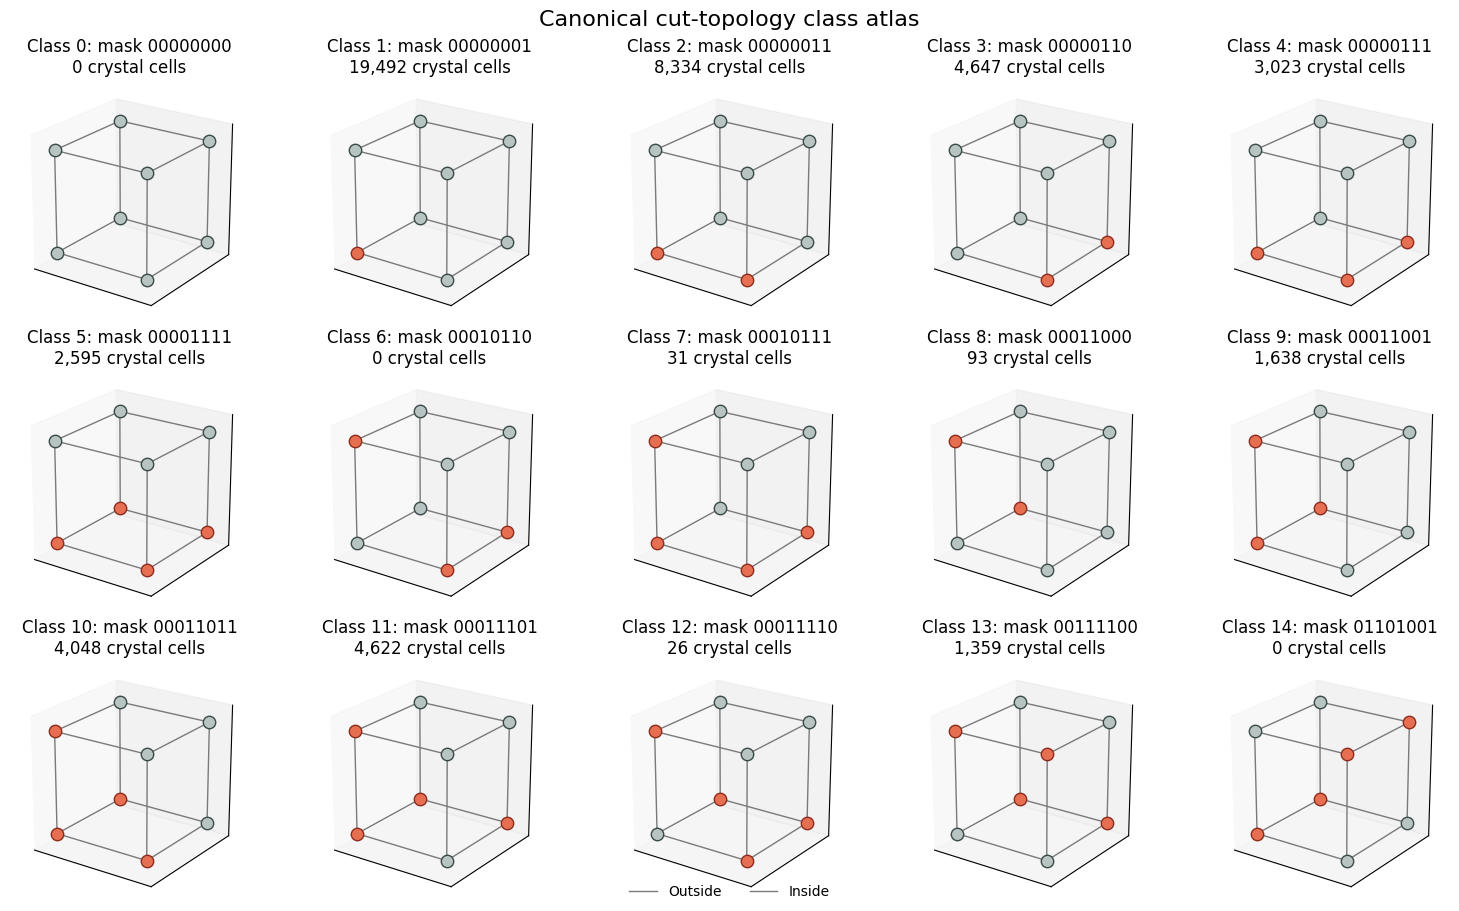

,canonical_topology_class,canonical_mask_decimal,canonical_mask_binary,inside_corners_in_representative,crystal_cells
0,0,0,00000000,0,0
1,1,1,00000001,1,19492
2,2,3,00000011,2,8334
3,3,6,00000110,2,4647
4,4,7,00000111,3,3023
5,5,15,00001111,4,2595
6,6,22,00010110,3,0
7,7,23,00010111,4,31
8,8,24,00011000,2,93
9,9,25,00011001,3,1638


In [19]:
from clean_simulation.internal_nn_runtime.cutcell_ml.classification_utils import MASK_TO_CLASS

# Each canonical mask is a representative of all rotations and complements in its class.
class_to_mask = {class_id: mask for mask, class_id in MASK_TO_CLASS.items()}
# Model order: [000, 100, 110, 010, 001, 101, 111, 011].
cube_vertices = np.asarray([
    (0, 0, 0), (1, 0, 0), (1, 1, 0), (0, 1, 0),
    (0, 0, 1), (1, 0, 1), (1, 1, 1), (0, 1, 1),
], dtype=float)
cube_edges = [
    (vertex, other)
    for vertex in range(8)
    for other in range(vertex + 1, 8)
    if np.count_nonzero(cube_vertices[vertex] != cube_vertices[other]) == 1
]
class_cell_counts = crystal_errors["canonical_topology_class"].value_counts()

figure = plt.figure(figsize=(15, 9), constrained_layout=True)
for class_id in range(15):
    axis = figure.add_subplot(3, 5, class_id + 1, projection="3d")
    canonical_mask = class_to_mask[class_id]
    is_inside = np.array([(canonical_mask >> vertex) & 1 for vertex in range(8)], dtype=bool)

    for start, stop in cube_edges:
        axis.plot3D(*cube_vertices[[start, stop]].T, color="#7a7a7a", linewidth=1.0)
    axis.scatter3D(
        *cube_vertices[~is_inside].T,
        s=80,
        color="#b8c4c2",
        edgecolors="#394a48",
        depthshade=False,
        label="Outside",
    )
    axis.scatter3D(
        *cube_vertices[is_inside].T,
        s=80,
        color="#e76f51",
        edgecolors="#8d2c1e",
        depthshade=False,
        label="Inside",
    )
    axis.set(
        xlim=(-0.15, 1.15), ylim=(-0.15, 1.15), zlim=(-0.15, 1.15),
        xticks=[], yticks=[], zticks=[],
        title=f"Class {class_id}: mask {canonical_mask:08b}\n{class_cell_counts.get(class_id, 0):,} crystal cells",
    )
    axis.set_box_aspect((1, 1, 1))
    axis.view_init(elev=22, azim=-55)

figure.legend(["Outside", "Inside"], loc="lower center", ncols=2, frameon=False)
figure.suptitle("Canonical cut-topology class atlas", fontsize=16)
plt.show()

class_atlas = pd.DataFrame({
    "canonical_topology_class": range(15),
    "canonical_mask_decimal": [class_to_mask[class_id] for class_id in range(15)],
    "canonical_mask_binary": [f"{class_to_mask[class_id]:08b}" for class_id in range(15)],
    "inside_corners_in_representative": [class_to_mask[class_id].bit_count() for class_id in range(15)],
    "crystal_cells": [class_cell_counts.get(class_id, 0) for class_id in range(15)],
})
display(class_atlas)
class_atlas.to_csv(OUTPUT_DIR / "crystal_canonical_topology_class_atlas.csv", index=False)

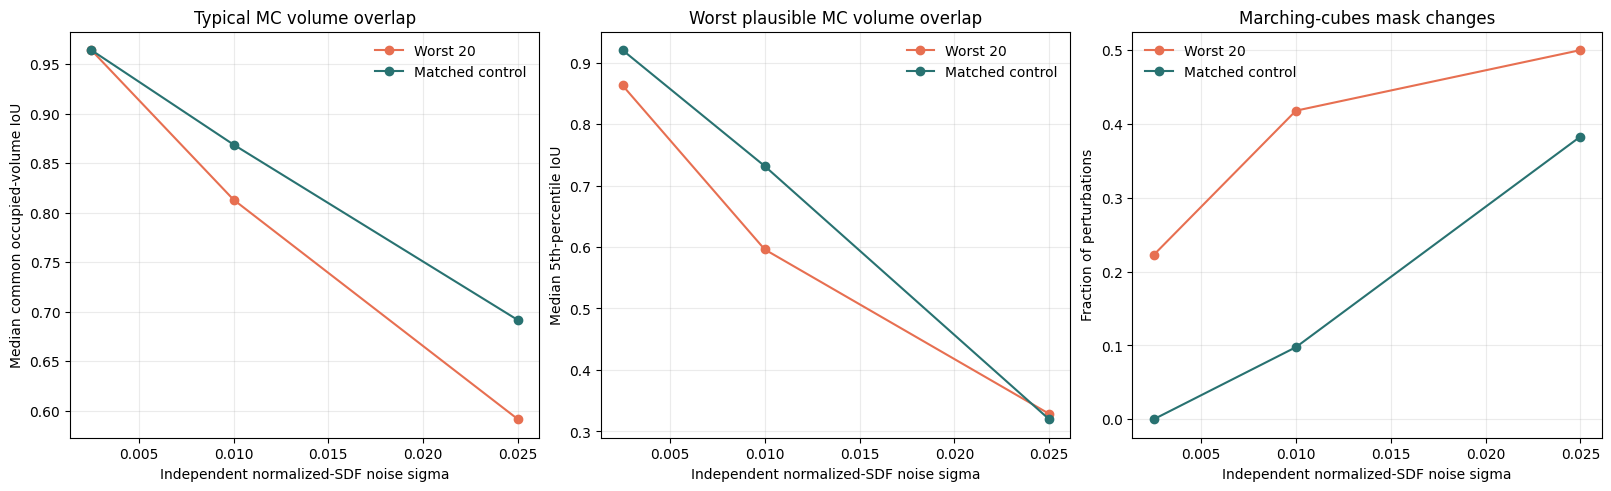

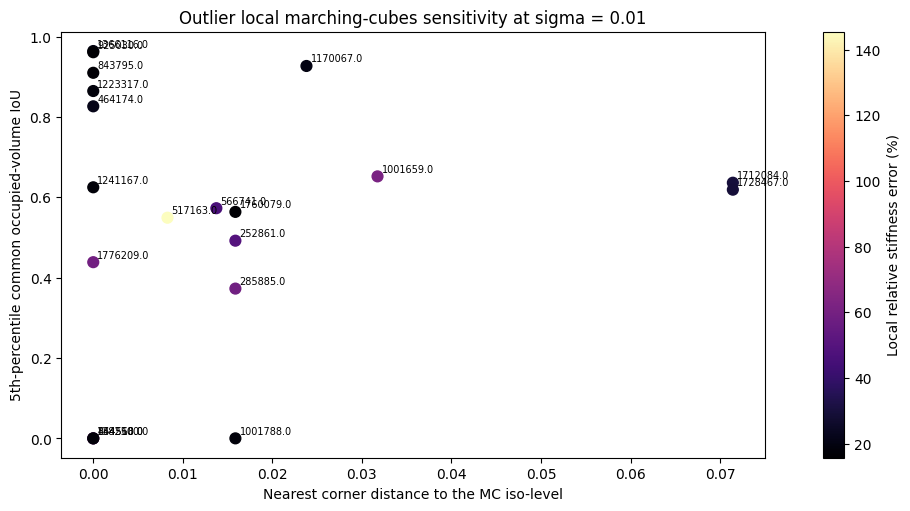

IoU is the common occupied trilinear-SDF volume divided by the union volume after perturbing the eight MC inputs.
Same-class, similar-volume controls found for 20 of 20 outliers.


,cohort,perturbation_sigma,cells,median_common_volume_iou,p05_common_volume_iou,median_volume_fraction_std,median_mask_change_rate
0,Matched control,0.0025,20,0.9643,0.9202,0.0040,0.00%
1,Matched control,0.0100,20,0.8688,0.7316,0.0137,9.77%
2,Matched control,0.0250,20,0.6915,0.3198,0.0364,38.28%
3,Worst 20,0.0025,20,0.9643,0.8629,0.0039,22.27%
4,Worst 20,0.0100,20,0.8131,0.5960,0.0142,41.80%
5,Worst 20,0.0250,20,0.5913,0.3286,0.0351,50.00%


In [13]:
MC_PERTURBATION_LEVELS = np.array([0.0025, 0.01, 0.025])
MC_PERTURBATION_DRAWS = 128
MC_RANDOM_SEED = 20260908

# Match each outlier to a lower-error cell in the same canonical class with
# the closest sampled volume fraction, isolating local MC conditioning.
mc_outliers = crystal_errors.nlargest(20, "relative_error_percent").copy()
control_pool = crystal_errors.loc[crystal_errors["relative_error_percent"] < crystal_p95]
mc_controls = []
for outlier in mc_outliers.itertuples():
    candidates = control_pool.loc[
        control_pool["canonical_topology_class"] == outlier.canonical_topology_class
    ]
    if not candidates.empty:
        control_index = (
            candidates["sampled_trilinear_volume_fraction"]
            .sub(outlier.sampled_trilinear_volume_fraction)
            .abs()
            .idxmin()
        )
        mc_controls.append(candidates.loc[control_index])
mc_controls = pd.DataFrame(mc_controls)
mc_study_cells = pd.concat((
    mc_outliers.assign(cohort="Worst 20"),
    mc_controls.assign(cohort="Matched control"),
), ignore_index=True)

corner_by_cell = pd.DataFrame(corner_sdf, index=cell_ids)
normalized_corners = 0.5 + corner_by_cell.loc[mc_study_cells["cell_id"]].to_numpy() / (
    2.0 * np.sqrt(3.0) * crystal_grid.dx
)
base_occupancy = (normalized_corners @ weights.T >= 0.5)
base_masks = ((normalized_corners > 0.5) * (1 << np.arange(8))).sum(axis=1)
rng = np.random.default_rng(MC_RANDOM_SEED)
mc_sensitivity_rows = []

for sigma in MC_PERTURBATION_LEVELS:
    perturbed = normalized_corners[:, None, :] + rng.normal(
        0.0, sigma, size=(len(mc_study_cells), MC_PERTURBATION_DRAWS, 8)
    )
    perturbed_occupancy = perturbed @ weights.T >= 0.5
    common_volume = np.logical_and(perturbed_occupancy, base_occupancy[:, None, :]).sum(axis=2)
    union_volume = np.logical_or(perturbed_occupancy, base_occupancy[:, None, :]).sum(axis=2)
    volume_iou = np.divide(common_volume, union_volume, out=np.ones_like(common_volume, dtype=float), where=union_volume > 0)
    perturbed_masks = ((perturbed > 0.5) * (1 << np.arange(8))).sum(axis=2)

    for row_index, row in enumerate(mc_study_cells.itertuples()):
        mc_sensitivity_rows.append({
            "cell_id": row.cell_id,
            "cohort": row.cohort,
            "canonical_topology_class": row.canonical_topology_class,
            "relative_error_percent": row.relative_error_percent,
            "sampled_trilinear_volume_fraction": row.sampled_trilinear_volume_fraction,
            "minimum_normalized_iso_distance": np.abs(normalized_corners[row_index] - 0.5).min(),
            "perturbation_sigma": sigma,
            "common_volume_iou_median": np.median(volume_iou[row_index]),
            "common_volume_iou_p05": np.quantile(volume_iou[row_index], 0.05),
            "volume_fraction_std": perturbed_occupancy[row_index].mean(axis=1).std(),
            "mask_change_rate": (perturbed_masks[row_index] != base_masks[row_index]).mean(),
        })
mc_sensitivity = pd.DataFrame(mc_sensitivity_rows)
mc_summary = mc_sensitivity.groupby(["cohort", "perturbation_sigma"], observed=True).agg(
    cells=("cell_id", "size"),
    median_common_volume_iou=("common_volume_iou_median", "median"),
    p05_common_volume_iou=("common_volume_iou_p05", "median"),
    median_volume_fraction_std=("volume_fraction_std", "median"),
    median_mask_change_rate=("mask_change_rate", "median"),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for cohort, color in [("Worst 20", "#e76f51"), ("Matched control", "#287271")]:
    summary = mc_summary.loc[mc_summary["cohort"] == cohort]
    axes[0].plot(summary["perturbation_sigma"], summary["median_common_volume_iou"], "o-", color=color, label=cohort)
    axes[1].plot(summary["perturbation_sigma"], summary["p05_common_volume_iou"], "o-", color=color, label=cohort)
    axes[2].plot(summary["perturbation_sigma"], summary["median_mask_change_rate"], "o-", color=color, label=cohort)
for axis, ylabel, title in [
    (axes[0], "Median common occupied-volume IoU", "Typical MC volume overlap"),
    (axes[1], "Median 5th-percentile IoU", "Worst plausible MC volume overlap"),
    (axes[2], "Fraction of perturbations", "Marching-cubes mask changes"),
]:
    axis.set(xlabel="Independent normalized-SDF noise sigma", ylabel=ylabel, title=title)
    axis.grid(alpha=0.25)
    axis.legend(frameon=False)
plt.show()

outlier_sigma = mc_sensitivity.loc[
    (mc_sensitivity["cohort"] == "Worst 20")
    & (mc_sensitivity["perturbation_sigma"] == 0.01)
]
fig, axis = plt.subplots(figsize=(9, 5), constrained_layout=True)
scatter = axis.scatter(
    outlier_sigma["minimum_normalized_iso_distance"],
    outlier_sigma["common_volume_iou_p05"],
    c=outlier_sigma["relative_error_percent"], cmap="magma", s=60,
)
for row in outlier_sigma.itertuples():
    axis.annotate(str(row.cell_id), (row.minimum_normalized_iso_distance, row.common_volume_iou_p05), xytext=(3, 3), textcoords="offset points", fontsize=7)
axis.set(xlabel="Nearest corner distance to the MC iso-level", ylabel="5th-percentile common occupied-volume IoU", title="Outlier local marching-cubes sensitivity at sigma = 0.01")
fig.colorbar(scatter, ax=axis, label="Local relative stiffness error (%)")
plt.show()

print("IoU is the common occupied trilinear-SDF volume divided by the union volume after perturbing the eight MC inputs.")
print(f"Same-class, similar-volume controls found for {len(mc_controls)} of {len(mc_outliers)} outliers.")
display(mc_summary.style.format({
    "perturbation_sigma": "{:.4f}", "median_common_volume_iou": "{:.4f}",
    "p05_common_volume_iou": "{:.4f}", "median_volume_fraction_std": "{:.4f}",
    "median_mask_change_rate": "{:.2%}",
}))
mc_sensitivity.to_csv(OUTPUT_DIR / "crystal_outlier_marching_cubes_volume_overlap_128cubed.csv", index=False)
mc_summary.to_csv(OUTPUT_DIR / "crystal_outlier_marching_cubes_volume_overlap_summary_128cubed.csv", index=False)

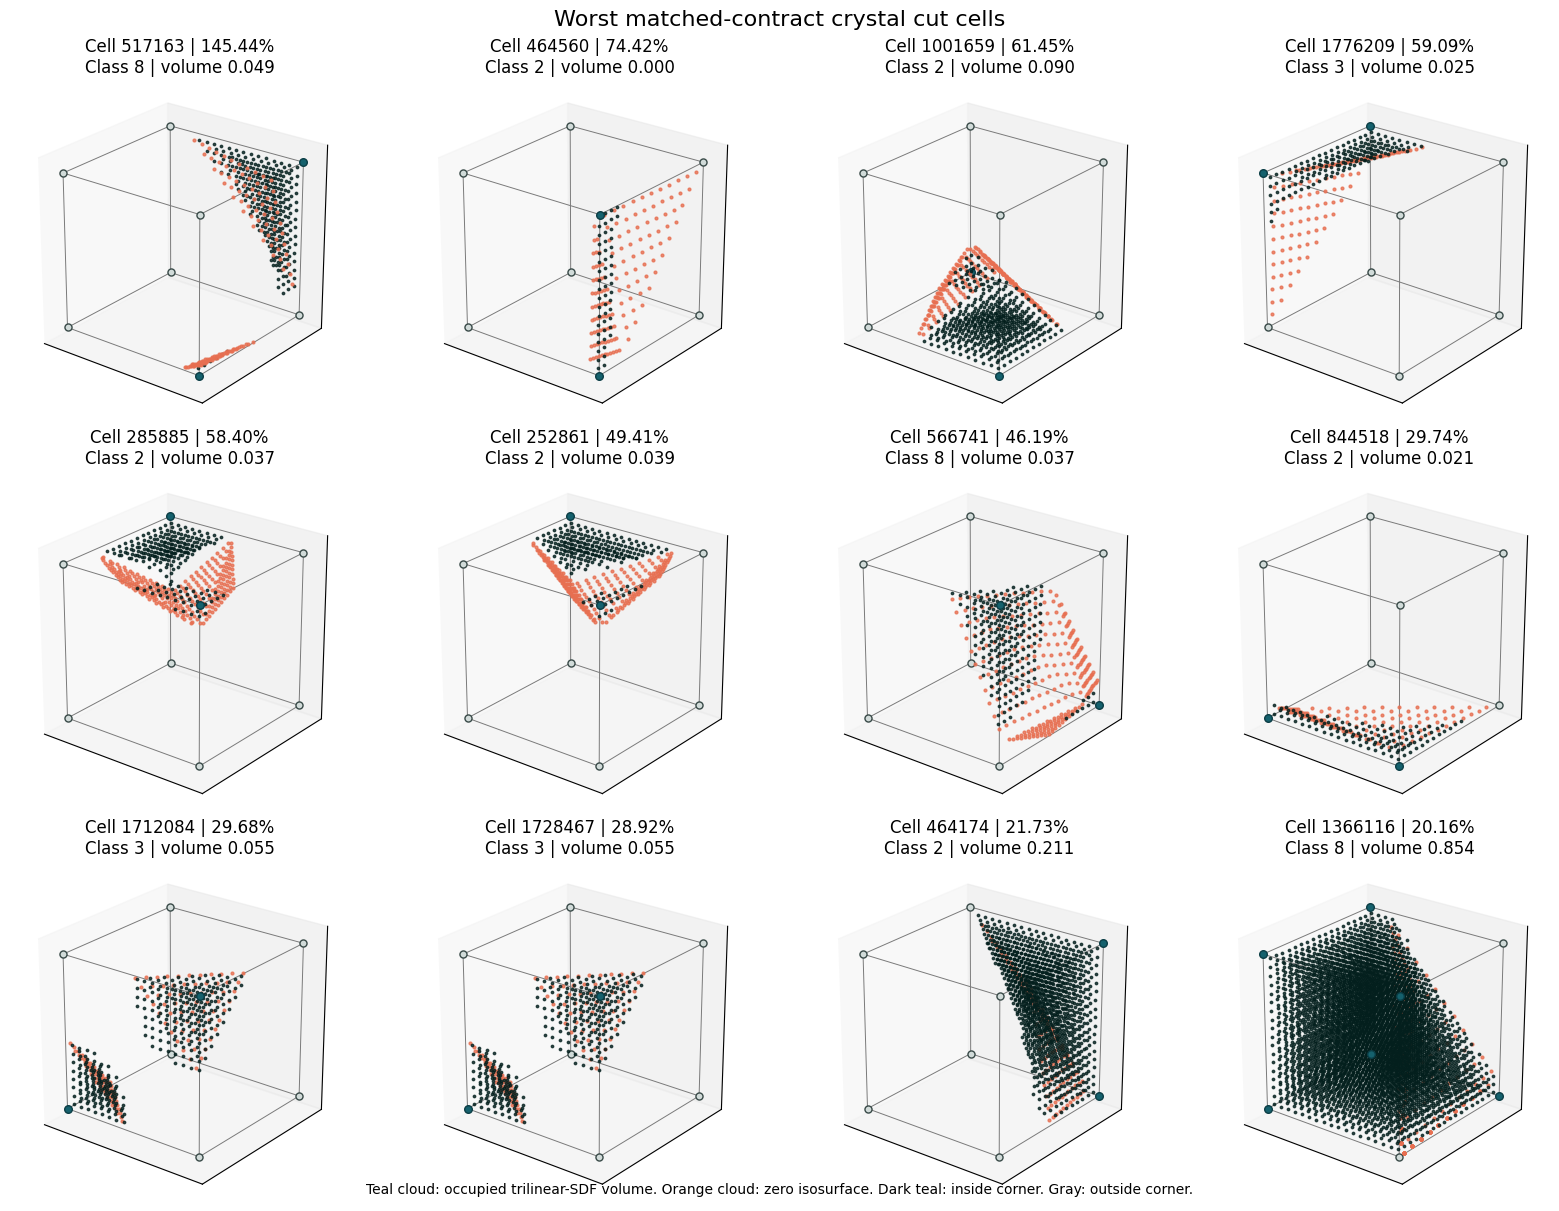

In [20]:
from skimage.measure import marching_cubes

WORST_CELL_GALLERY_COUNT = 12
GALLERY_VOLUME_SAMPLES_PER_AXIS = 18
GALLERY_SURFACE_POINTS_PER_FACE = 12
worst_cell_gallery = crystal_errors.nlargest(WORST_CELL_GALLERY_COUNT, "relative_error_percent").copy()
corner_by_cell = pd.DataFrame(corner_sdf, index=cell_ids)

sample_axis = (np.arange(GALLERY_VOLUME_SAMPLES_PER_AXIS) + 0.5) / GALLERY_VOLUME_SAMPLES_PER_AXIS
sample_x, sample_y, sample_z = np.meshgrid(sample_axis, sample_axis, sample_axis, indexing="ij")
gallery_points = np.column_stack((sample_x.ravel(), sample_y.ravel(), sample_z.ravel()))
gallery_weights = np.column_stack((
    (1 - gallery_points[:, 0]) * (1 - gallery_points[:, 1]) * (1 - gallery_points[:, 2]),
    gallery_points[:, 0] * (1 - gallery_points[:, 1]) * (1 - gallery_points[:, 2]),
    gallery_points[:, 0] * gallery_points[:, 1] * (1 - gallery_points[:, 2]),
    (1 - gallery_points[:, 0]) * gallery_points[:, 1] * (1 - gallery_points[:, 2]),
    (1 - gallery_points[:, 0]) * (1 - gallery_points[:, 1]) * gallery_points[:, 2],
    gallery_points[:, 0] * (1 - gallery_points[:, 1]) * gallery_points[:, 2],
    gallery_points[:, 0] * gallery_points[:, 1] * gallery_points[:, 2],
    (1 - gallery_points[:, 0]) * gallery_points[:, 1] * gallery_points[:, 2],
))

# The model order is [000, 100, 110, 010, 001, 101, 111, 011].
# Construct the field explicitly for skimage's [x, y, z] indexing.
def model_corners_to_xyz_field(values):
    field = np.empty((2, 2, 2), dtype=float)
    field[0, 0, 0], field[1, 0, 0], field[1, 1, 0], field[0, 1, 0] = values[:4]
    field[0, 0, 1], field[1, 0, 1], field[1, 1, 1], field[0, 1, 1] = values[4:]
    return field

figure = plt.figure(figsize=(16, 12), constrained_layout=True)
for panel_index, row in enumerate(worst_cell_gallery.itertuples(), start=1):
    axis = figure.add_subplot(3, 4, panel_index, projection="3d")
    local_sdf = corner_by_cell.loc[row.cell_id].to_numpy()
    normalized_sdf = 0.5 + local_sdf / (2.0 * np.sqrt(3.0) * crystal_grid.dx)
    occupied_points = gallery_points[(gallery_weights @ normalized_sdf) >= 0.5]
    vertices, faces, _, _ = marching_cubes(model_corners_to_xyz_field(normalized_sdf), level=0.5)

    face_points = []
    barycentric_axis = (np.arange(GALLERY_SURFACE_POINTS_PER_FACE) + 0.5) / GALLERY_SURFACE_POINTS_PER_FACE
    for face in faces:
        first, second, third = vertices[face]
        for first_weight in barycentric_axis:
            for second_weight in barycentric_axis:
                if first_weight + second_weight < 1.0:
                    face_points.append(
                        first_weight * first + second_weight * second + (1.0 - first_weight - second_weight) * third
                    )
    surface_points = np.asarray(face_points)

    axis.scatter3D(*occupied_points.T, s=3, color="#031f1d", alpha=0.78, depthshade=False)
    axis.scatter3D(*surface_points.T, s=4, color="#e76f51", alpha=0.8, depthshade=False)

    inside_corners = normalized_sdf > 0.5
    axis.scatter3D(*cube_vertices[~inside_corners].T, s=26, color="#d1dbd9", edgecolors="#394a48", depthshade=False)
    axis.scatter3D(*cube_vertices[inside_corners].T, s=30, color="#15616d", edgecolors="#0b3d45", depthshade=False)
    for start, stop in cube_edges:
        axis.plot3D(*cube_vertices[[start, stop]].T, color="#7a7a7a", linewidth=0.7)
    axis.set(
        xlim=(-0.1, 1.1), ylim=(-0.1, 1.1), zlim=(-0.1, 1.1),
        xticks=[], yticks=[], zticks=[],
        title=(
            f"Cell {row.cell_id} | {row.relative_error_percent:.2f}%\n"
            f"Class {row.canonical_topology_class} | volume {row.sampled_trilinear_volume_fraction:.3f}"
        ),
    )
    axis.set_box_aspect((1, 1, 1))
    axis.view_init(elev=24, azim=-52)

figure.text(0.5, 0.01, "Teal cloud: occupied trilinear-SDF volume. Orange cloud: zero isosurface. Dark teal: inside corner. Gray: outside corner.", ha="center")
figure.suptitle("Worst matched-contract crystal cut cells", fontsize=16)
plt.show()

worst_cell_gallery[[
    "cell_id", "relative_error_percent", "canonical_topology_class",
    "sampled_trilinear_volume_fraction", "minimum_absolute_lattice_sdf",
    "lattice_sdf_span", "mean_lattice_sdf",
]].to_csv(OUTPUT_DIR / "crystal_worst_cell_gallery_128cubed.csv", index=False)

## Hanging-Sphere Displacement Diagnostics

This separate diagnostic evaluates the archived $128^3$ hanging-sphere NN and QuESo fields from the `physical_fixed_support_local` run. Every displacement metric uses the intersection of nodes incident to the archived active cells, independently reconstructed for both fields; nodes outside that common physical support are excluded. To remain stable at constrained or near-zero-displacement nodes, nodewise vector error is normalized by the maximum QuESo displacement magnitude over that support, rather than dividing independently by each nodal magnitude.

To identify the input regimes associated with nodal errors, the notebook reuses the archived study STL and its archived QuESo cut-cell indices, then runs the same mesh-based `prepare_nn_inputs` SDF procedure that fed the NN. A node is assigned an SDF feature only when it is incident to at least one NN-predicted cut cell. The model-input analysis therefore does not infer signed distance from the hanging-sphere formula and does not attribute an input feature to nodes whose incident matrices were all analytic full-cell matrices. Grid coordinates are normalized to $[0, 1]^3$ only for spatial plotting. These displacement results are a benchmark-field diagnostic and are not a displacement solve for the medium crystal checkpoint above.

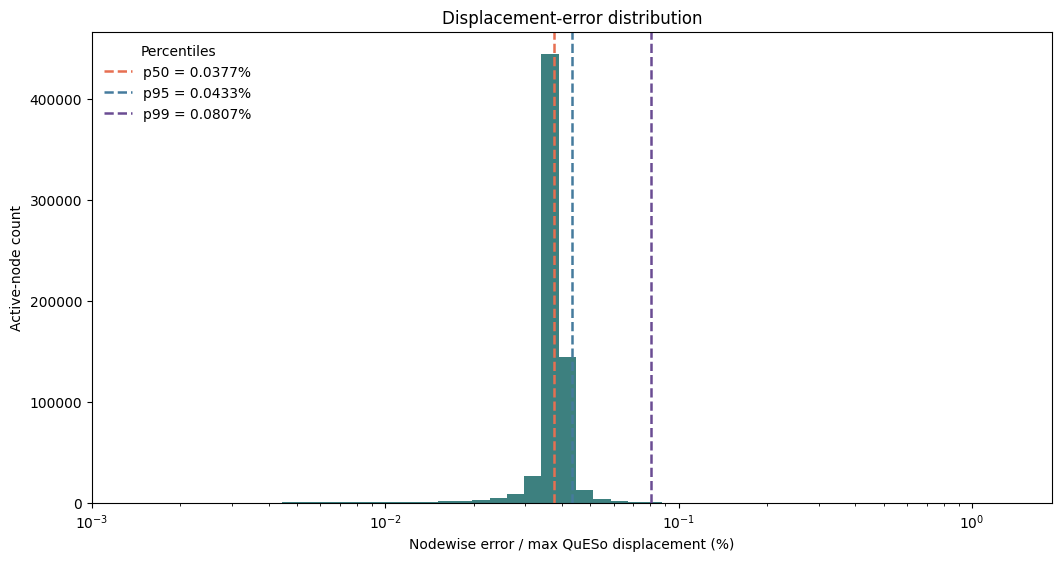

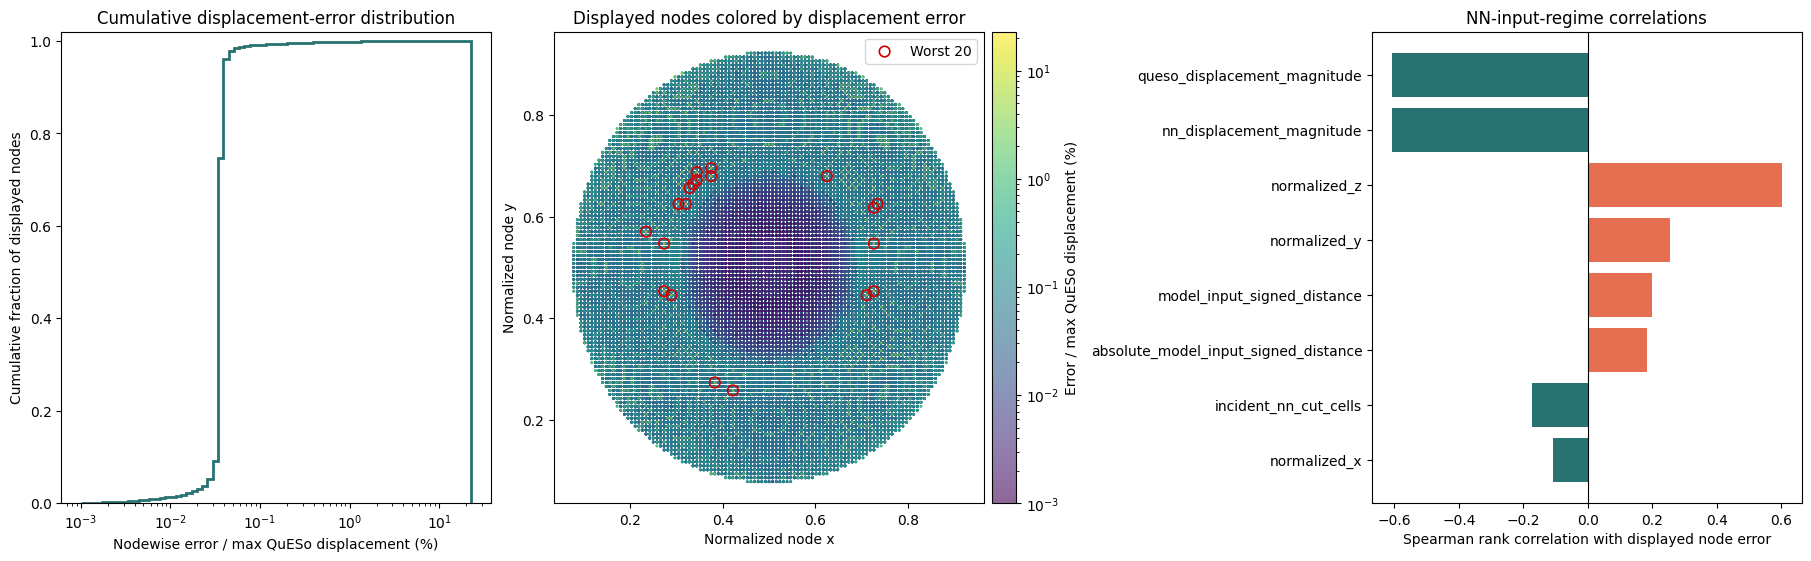

QuESo physical active nodes: 686,301
NN physical active nodes: 686,301
Shared physical active nodes used by displacement metrics: 686,301
Excluded QuESo-only nodes: 0
Excluded NN-only nodes: 0
Filtered nodes below 1e-03%: 8,216
Displayed nodes at or above 1e-03%: 678,085
Displayed nodes incident to NN-predicted cut cells: 99,570
NN vs QuESo relative L2 displacement error: 0.1780%
Worst 20 displayed normalized node errors: 8.632% to 22.925%
Highest p95 NN-input signed-distance regime: (0.162, 0.227]; p95=2.3582%, mean=0.4698%


,population,nodes,spearman_rank,pearson
0,shared physical nodes,686301,-0.0393,0.0185
1,displayed NN-predicted cut-cell nodes,99570,-0.6092,-0.0869


,node_id,normalized_node_error_percent,nodewise_relative_error,absolute_node_error,queso_displacement_magnitude,nn_displacement_magnitude,model_input_signed_distance,absolute_model_input_signed_distance,incident_nn_cut_cells,normalized_x,normalized_y,normalized_z
96729,591575,22.9252,50.5520%,3.8567e-03,7.6292e-03,1.0140e-02,0.19969,0.19969,1,0.2734,0.5469,0.8594
141526,692712,18.4452,41.4899%,3.1030e-03,7.4790e-03,9.1083e-03,0.19968,0.19968,1,0.3203,0.6250,0.8672
589663,1555205,17.6820,38.9899%,2.9746e-03,7.6292e-03,8.0264e-03,0.19969,0.19969,1,0.7266,0.4531,0.8594
65359,508753,16.2992,25.6060%,2.7420e-03,1.0708e-02,1.2554e-02,0.20562,0.20562,1,0.2344,0.5703,0.8281
590779,1556753,15.8251,34.8957%,2.6622e-03,7.6291e-03,8.7214e-03,0.19969,0.19969,1,0.7266,0.5469,0.8594
199781,810102,13.7089,30.5504%,2.3062e-03,7.5490e-03,7.9632e-03,0.19924,0.19924,1,0.3750,0.6797,0.8672
95613,590027,13.0852,28.8537%,2.2013e-03,7.6292e-03,8.0824e-03,0.19969,0.19969,1,0.2734,0.4531,0.8594
575625,1521795,12.1383,27.9879%,2.0420e-03,7.2961e-03,7.5915e-03,0.19296,0.19296,1,0.7109,0.4453,0.8672
166054,743408,11.8232,25.2925%,1.9890e-03,7.8640e-03,8.2862e-03,0.20876,0.20876,1,0.3438,0.6719,0.8594
199967,810359,11.7198,24.5450%,1.9716e-03,8.0327e-03,8.5662e-03,0.20387,0.20387,1,0.3750,0.6953,0.8594


,variable,group,nodes,median,p95,mean
0,queso_displacement_magnitude,"(-0.000999719, 0.0116]",9957,0.0491%,0.2489%,0.1719%
1,queso_displacement_magnitude,"(0.0116, 0.0132]",9957,0.0420%,0.2988%,0.1216%
2,queso_displacement_magnitude,"(0.0132, 0.0138]",9957,0.0406%,0.3018%,0.1228%
3,queso_displacement_magnitude,"(0.0138, 0.0141]",9957,0.0399%,0.2667%,0.1015%
4,queso_displacement_magnitude,"(0.0141, 0.0144]",9957,0.0394%,0.0732%,0.0702%
5,queso_displacement_magnitude,"(0.0144, 0.0147]",9957,0.0391%,0.0682%,0.0561%
6,queso_displacement_magnitude,"(0.0147, 0.015]",9957,0.0387%,0.1136%,0.0544%
7,queso_displacement_magnitude,"(0.015, 0.0155]",9957,0.0384%,0.0709%,0.0508%
8,queso_displacement_magnitude,"(0.0155, 0.0161]",9957,0.0380%,0.0650%,0.0478%
9,queso_displacement_magnitude,"(0.0161, 0.0168]",9957,0.0375%,0.0534%,0.0441%


In [8]:
from matplotlib.colors import LogNorm
import sys

import torch

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clean_simulation.bootstrap import configure_legacy_imports
from clean_simulation.internal_nn_runtime.cutcell_bridge import prepare_nn_inputs

DISPLACEMENT_ARCHIVE_DIR = (
    ROOT / "clean_simulation" / "outputs" / "sphere_displacement_convergence_physical_fixed_support_local"
    / "planar_cap_plane_hard_constraints"
)
DISPLACEMENT_RESOLUTION = 128
DISPLACEMENT_BOUNDS = np.array(((-9.0, -9.0, -9.0), (9.0, 9.0, 9.0)), dtype=np.float64)
DISPLACEMENT_MESH_DIR = DISPLACEMENT_ARCHIVE_DIR.parent / f"queso_matrix_free_{DISPLACEMENT_RESOLUTION}cubed"
DISPLACEMENT_STL = DISPLACEMENT_MESH_DIR / "study_geometry_surface.stl"
DISPLACEMENT_CUT_CACHE = DISPLACEMENT_MESH_DIR / "queso_cut_stiffness.pt"
NODEWISE_REFERENCE_FLOOR_FRACTION = 1.0e-4
DISPLAY_ERROR_FLOOR_PERCENT = 1.0e-3


def active_node_ids(active_cells: np.ndarray, resolution: int) -> np.ndarray:
    cells = np.unique(np.asarray(active_cells, dtype=np.int64))
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((
        0, node_side * node_side, node_side * node_side + node_side, node_side,
        1, node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1,
    ))
    return np.unique((base[:, None] + offsets).reshape(-1))


def load_archived_displacement_field(framework: str) -> dict[str, np.ndarray]:
    archive_path = DISPLACEMENT_ARCHIVE_DIR / f"hanging_sphere_{framework}_displacement_{DISPLACEMENT_RESOLUTION}cubed.npz"
    if not archive_path.is_file():
        raise FileNotFoundError(f"Missing archived displacement field: {archive_path}")
    with np.load(archive_path, allow_pickle=True) as archive:
        return {
            "u_nodes": np.asarray(archive["u_nodes"], dtype=np.float64),
            "active_cells": np.asarray(archive["active_cells"], dtype=np.int64),
            "active_nodes": np.asarray(archive["active_nodes"], dtype=np.int64),
        }


def model_input_sdf_by_node() -> tuple[np.ndarray, np.ndarray]:
    """Return raw model-input SDF and incident predicted-cut-cell counts per grid node."""
    if not DISPLACEMENT_STL.is_file() or not DISPLACEMENT_CUT_CACHE.is_file():
        raise FileNotFoundError("The archived study STL and QuESo cut-cell cache are required for model-input diagnostics.")
    configure_legacy_imports(ROOT)
    from constants import Material
    from geometry import HexGrid
    from volume_factory import VolumeFactory

    grid = HexGrid(bounds=DISPLACEMENT_BOUNDS.tolist(), resolution=[DISPLACEMENT_RESOLUTION] * 3, device="cpu")
    volume = VolumeFactory.from_file(DISPLACEMENT_STL)
    cut_cache = torch.load(DISPLACEMENT_CUT_CACHE, map_location="cpu", weights_only=True)
    cut_cells = cut_cache["indices"].to(dtype=torch.int64)
    d_normalized, _, h_ref = prepare_nn_inputs(
        grid=grid,
        volume=volume,
        partial_indices=cut_cells,
        material=Material(E=1.0e6, nu=0.3),
        poly_order=1,
        sdf_device="cuda" if torch.cuda.is_available() else "cpu",
    )
    raw_sdf = (0.5 - d_normalized.numpy()) * (2.0 * np.sqrt(3.0) * h_ref)
    cell_ids = cut_cells.numpy()
    node_side = DISPLACEMENT_RESOLUTION + 1
    i = cell_ids // (DISPLACEMENT_RESOLUTION ** 2)
    j = (cell_ids // DISPLACEMENT_RESOLUTION) % DISPLACEMENT_RESOLUTION
    k = cell_ids % DISPLACEMENT_RESOLUTION
    base = (i * node_side + j) * node_side + k
    offsets = np.array((
        0, node_side * node_side, node_side * node_side + node_side, node_side,
        1, node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1,
    ))
    cell_node_ids = (base[:, None] + offsets).reshape(-1)
    node_sdf_sum = np.zeros(node_side ** 3, dtype=np.float64)
    node_sdf_count = np.zeros(node_side ** 3, dtype=np.int64)
    np.add.at(node_sdf_sum, cell_node_ids, raw_sdf.reshape(-1))
    np.add.at(node_sdf_count, cell_node_ids, 1)
    mean_sdf = np.full(node_side ** 3, np.nan)
    np.divide(node_sdf_sum, node_sdf_count, out=mean_sdf, where=node_sdf_count > 0)
    return mean_sdf, node_sdf_count


queso_displacement = load_archived_displacement_field("queso")
nn_displacement = load_archived_displacement_field("nn")
queso_active_nodes = active_node_ids(queso_displacement["active_cells"], DISPLACEMENT_RESOLUTION)
nn_active_nodes = active_node_ids(nn_displacement["active_cells"], DISPLACEMENT_RESOLUTION)
common_active_nodes = np.intersect1d(queso_active_nodes, nn_active_nodes, assume_unique=True)
queso_only_nodes = np.setdiff1d(queso_active_nodes, common_active_nodes, assume_unique=True)
nn_only_nodes = np.setdiff1d(nn_active_nodes, common_active_nodes, assume_unique=True)

if not np.array_equal(np.unique(queso_displacement["active_nodes"]), queso_active_nodes):
    raise RuntimeError("QuESo archive active_nodes does not match the nodes incident to its active cells.")
if not np.array_equal(np.unique(nn_displacement["active_nodes"]), nn_active_nodes):
    raise RuntimeError("NN archive active_nodes does not match the nodes incident to its active cells.")
if not len(common_active_nodes):
    raise RuntimeError("The archived NN and QuESo fields have no common physical active-node support.")

active_nodes = common_active_nodes
reference_u = queso_displacement["u_nodes"][active_nodes]
predicted_u = nn_displacement["u_nodes"][active_nodes]
reference_magnitude = np.linalg.norm(reference_u, axis=1)
absolute_node_error = np.linalg.norm(predicted_u - reference_u, axis=1)
reference_peak = max(float(reference_magnitude.max()), np.finfo(np.float64).tiny)
nodewise_error_percent = 100.0 * absolute_node_error / reference_peak
reference_floor = reference_peak * NODEWISE_REFERENCE_FLOOR_FRACTION
valid_relative_nodes = reference_magnitude > reference_floor
nodewise_relative_error = np.full(len(active_nodes), np.nan)
nodewise_relative_error[valid_relative_nodes] = absolute_node_error[valid_relative_nodes] / reference_magnitude[valid_relative_nodes]

node_side = DISPLACEMENT_RESOLUTION + 1
i = active_nodes // (node_side * node_side)
j = (active_nodes // node_side) % node_side
k = active_nodes % node_side
node_indices = np.column_stack((i, j, k))
model_input_sdf, incident_cut_cell_count = model_input_sdf_by_node()
nodal_model_sdf = model_input_sdf[active_nodes]
nodal_cut_cell_count = incident_cut_cell_count[active_nodes]

displacement_diagnostics = pd.DataFrame({
    "node_id": active_nodes,
    "normalized_node_error_percent": nodewise_error_percent,
    "nodewise_relative_error": nodewise_relative_error,
    "absolute_node_error": absolute_node_error,
    "queso_displacement_magnitude": reference_magnitude,
    "nn_displacement_magnitude": np.linalg.norm(predicted_u, axis=1),
    "model_input_signed_distance": nodal_model_sdf,
    "absolute_model_input_signed_distance": np.abs(nodal_model_sdf),
    "incident_nn_cut_cells": nodal_cut_cell_count,
    "normalized_x": node_indices[:, 0] / DISPLACEMENT_RESOLUTION,
    "normalized_y": node_indices[:, 1] / DISPLACEMENT_RESOLUTION,
    "normalized_z": node_indices[:, 2] / DISPLACEMENT_RESOLUTION,
})
DISPLACEMENT_ERROR_COLUMN = "normalized_node_error_percent"
displayed_displacement_diagnostics = displacement_diagnostics.loc[
    displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN] >= DISPLAY_ERROR_FLOOR_PERCENT
].copy()
if displayed_displacement_diagnostics.empty:
    raise RuntimeError(f"No active nodes have displacement error at least {DISPLAY_ERROR_FLOOR_PERCENT:.0e}%.")
model_input_nodes = displayed_displacement_diagnostics.loc[
    displayed_displacement_diagnostics["incident_nn_cut_cells"] > 0
].copy()
DISPLACEMENT_EXPLANATORY_COLUMNS = [
    "queso_displacement_magnitude",
    "nn_displacement_magnitude",
    "model_input_signed_distance",
    "absolute_model_input_signed_distance",
    "incident_nn_cut_cells",
    "normalized_x",
    "normalized_y",
    "normalized_z",
]
displacement_correlations = (
    model_input_nodes[DISPLACEMENT_EXPLANATORY_COLUMNS + [DISPLACEMENT_ERROR_COLUMN]]
    .corr(method="spearman")[DISPLACEMENT_ERROR_COLUMN]
    .drop(DISPLACEMENT_ERROR_COLUMN)
    .sort_values(key=np.abs, ascending=False)
)
reference_error_correlations = pd.DataFrame({
    "population": ["shared physical nodes", "displayed NN-predicted cut-cell nodes"],
    "nodes": [len(displacement_diagnostics), len(model_input_nodes)],
    "spearman_rank": [
        displacement_diagnostics["queso_displacement_magnitude"].corr(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN], method="spearman"),
        model_input_nodes["queso_displacement_magnitude"].corr(model_input_nodes[DISPLACEMENT_ERROR_COLUMN], method="spearman"),
    ],
    "pearson": [
        displacement_diagnostics["queso_displacement_magnitude"].corr(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN], method="pearson"),
        model_input_nodes["queso_displacement_magnitude"].corr(model_input_nodes[DISPLACEMENT_ERROR_COLUMN], method="pearson"),
    ],
})
worst_displacement_nodes = displayed_displacement_diagnostics.nlargest(20, DISPLACEMENT_ERROR_COLUMN)
plot_errors = displayed_displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN]
filtered_node_count = len(displacement_diagnostics) - len(displayed_displacement_diagnostics)
error_ceiling = float(plot_errors.max())
distribution_xmax = float(plot_errors.quantile(0.999))

fig_distribution, distribution_axis = plt.subplots(figsize=(10.5, 5.5), constrained_layout=True)
distribution_axis.hist(plot_errors, bins=bins, color="#287271", alpha=0.9)
distribution_axis.set_xscale("log")
distribution_axis.set(
    xlabel="Nodewise error / max QuESo displacement (%)",
    ylabel="Active-node count",
    title="Displacement-error distribution",
)
distribution_axis.set_xlim(DISPLAY_ERROR_FLOOR_PERCENT, distribution_xmax)
for percentile, color in [(0.50, "#e76f51"), (0.95, "#457b9d"), (0.99, "#6a4c93")]:
    value = float(plot_errors.quantile(percentile))
    distribution_axis.axvline(value, color=color, linestyle="--", linewidth=1.8, label=f"p{int(percentile * 100)} = {value:.3g}%")
distribution_axis.legend(title="Percentiles", frameon=False, loc="upper left")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
axes[0].hist(plot_errors, bins=bins, density=True, cumulative=True, histtype="step", linewidth=2.0, color="#287271")
axes[0].set_xscale("log")
axes[0].set(xlabel="Nodewise error / max QuESo displacement (%)", ylabel="Cumulative fraction of displayed nodes", ylim=(0.0, 1.02), title="Cumulative displacement-error distribution")

scatter = axes[1].scatter(
    displayed_displacement_diagnostics["normalized_x"], displayed_displacement_diagnostics["normalized_y"], c=plot_errors,
    s=4, cmap="viridis", norm=LogNorm(vmin=DISPLAY_ERROR_FLOOR_PERCENT, vmax=error_ceiling), alpha=0.6, linewidths=0,
)
axes[1].scatter(worst_displacement_nodes["normalized_x"], worst_displacement_nodes["normalized_y"], facecolors="none", edgecolors="#d00000", s=58, linewidths=1.2, label="Worst 20")
axes[1].set(xlabel="Normalized node x", ylabel="Normalized node y", title="Displayed nodes colored by displacement error")
axes[1].legend(loc="upper right")
fig.colorbar(scatter, ax=axes[1], label="Error / max QuESo displacement (%)", pad=0.02)

correlation_colors = np.where(displacement_correlations.values < 0.0, "#287271", "#e76f51")
axes[2].barh(displacement_correlations.index, displacement_correlations.values, color=correlation_colors)
axes[2].axvline(0.0, color="black", linewidth=0.8)
axes[2].set(xlabel="Spearman rank correlation with displayed node error", title="NN-input-regime correlations")
axes[2].invert_yaxis()
plt.show()

conditional_displacement_summaries = []
for variable in ["queso_displacement_magnitude", "model_input_signed_distance", "absolute_model_input_signed_distance", "normalized_z"]:
    groups = pd.qcut(model_input_nodes[variable], q=10, duplicates="drop")
    grouped = model_input_nodes.groupby(groups, observed=True)[DISPLACEMENT_ERROR_COLUMN].agg(
        nodes="size", median="median", p95=lambda values: values.quantile(0.95), mean="mean",
    ).reset_index(names="group")
    grouped.insert(0, "variable", variable)
    conditional_displacement_summaries.append(grouped)

conditional_displacement_summary = pd.concat(conditional_displacement_summaries, ignore_index=True)
signed_distance_summary = conditional_displacement_summary.loc[
    conditional_displacement_summary["variable"] == "model_input_signed_distance"
]
worst_signed_distance_regime = signed_distance_summary.loc[signed_distance_summary["p95"].idxmax()]
worst_displacement_node_table = worst_displacement_nodes[[
    "node_id", "normalized_node_error_percent", "nodewise_relative_error", "absolute_node_error",
    "queso_displacement_magnitude", "nn_displacement_magnitude", "model_input_signed_distance",
    "absolute_model_input_signed_distance", "incident_nn_cut_cells", "normalized_x", "normalized_y", "normalized_z",
]].sort_values(DISPLACEMENT_ERROR_COLUMN, ascending=False)

relative_l2_displacement_error = np.linalg.norm(predicted_u - reference_u) / max(np.linalg.norm(reference_u), np.finfo(np.float64).tiny)
print(f"QuESo physical active nodes: {len(queso_active_nodes):,}")
print(f"NN physical active nodes: {len(nn_active_nodes):,}")
print(f"Shared physical active nodes used by displacement metrics: {len(active_nodes):,}")
print(f"Excluded QuESo-only nodes: {len(queso_only_nodes):,}")
print(f"Excluded NN-only nodes: {len(nn_only_nodes):,}")
print(f"Filtered nodes below {DISPLAY_ERROR_FLOOR_PERCENT:.0e}%: {filtered_node_count:,}")
print(f"Displayed nodes at or above {DISPLAY_ERROR_FLOOR_PERCENT:.0e}%: {len(displayed_displacement_diagnostics):,}")
print(f"Displayed nodes incident to NN-predicted cut cells: {len(model_input_nodes):,}")
print(f"NN vs QuESo relative L2 displacement error: {relative_l2_displacement_error:.4%}")
print(f"Worst 20 displayed normalized node errors: {worst_displacement_nodes[DISPLACEMENT_ERROR_COLUMN].min():.3f}% to {worst_displacement_nodes[DISPLACEMENT_ERROR_COLUMN].max():.3f}%")
print(f"Highest p95 NN-input signed-distance regime: {worst_signed_distance_regime.group}; p95={worst_signed_distance_regime.p95:.4f}%, mean={worst_signed_distance_regime['mean']:.4f}%")
display(reference_error_correlations.style.format({"spearman_rank": "{:.4f}", "pearson": "{:.4f}"}))
display(worst_displacement_node_table.style.format({
    "normalized_node_error_percent": "{:.4f}", "nodewise_relative_error": "{:.4%}", "absolute_node_error": "{:.4e}",
    "queso_displacement_magnitude": "{:.4e}", "nn_displacement_magnitude": "{:.4e}",
    "model_input_signed_distance": "{:.5f}", "absolute_model_input_signed_distance": "{:.5f}",
    "normalized_x": "{:.4f}", "normalized_y": "{:.4f}", "normalized_z": "{:.4f}",
}))
display(conditional_displacement_summary.style.format({"median": "{:.4f}%", "p95": "{:.4f}%", "mean": "{:.4f}%"}))

In [ ]:
legacy_baseline = pd.read_csv(CONVERGENCE_FILE)
legacy_128 = legacy_baseline.loc[
    (legacy_baseline["resolution"] == WORKING_RESOLUTION)
    & (legacy_baseline["method"].isin(["queso", "nn", "naive", "weighted"])),
    ["method", "cells", "mean_relative_error", "median_relative_error", "p95_relative_error", "max_relative_error"],
].copy()
legacy_128 = legacy_128.rename(columns={
    "mean_relative_error": "legacy_mean_cellwise_relative_error",
    "median_relative_error": "legacy_median_cellwise_relative_error",
    "p95_relative_error": "legacy_p95_cellwise_relative_error",
    "max_relative_error": "legacy_max_cellwise_relative_error",
})
legacy_128["reference"] = f"QuESo {REFERENCE_RESOLUTION}^3"
legacy_128["candidate_resolution"] = WORKING_RESOLUTION
legacy_128 = legacy_128.sort_values("method").reset_index(drop=True)

display(legacy_128.style.format({
    "legacy_mean_cellwise_relative_error": "{:.3%}",
    "legacy_median_cellwise_relative_error": "{:.3%}",
    "legacy_p95_cellwise_relative_error": "{:.3%}",
    "legacy_max_cellwise_relative_error": "{:.3%}",
}))

legacy_queso_128 = legacy_128.loc[legacy_128["method"] == "queso"].iloc[0]
print(
    "Legacy, unweighted cellwise baseline only: "
    f"QuESo {WORKING_RESOLUTION}^3 versus {REFERENCE_RESOLUTION}^3 has "
    f"median={legacy_queso_128.legacy_median_cellwise_relative_error:.3%}, "
    f"mean={legacy_queso_128.legacy_mean_cellwise_relative_error:.3%}, "
    f"p95={legacy_queso_128.legacy_p95_cellwise_relative_error:.3%}."
)

,method,cells,legacy_mean_cellwise_relative_error,legacy_median_cellwise_relative_error,legacy_p95_cellwise_relative_error,legacy_max_cellwise_relative_error,reference,candidate_resolution
0,naive,51999,2048.793%,541.146%,9139.817%,50757.122%,QuESo 512^3,128
1,nn,50823,312.381%,115.088%,1152.023%,5765.697%,QuESo 512^3,128
2,queso,51999,310.741%,109.789%,1152.018%,5679.213%,QuESo 512^3,128
3,weighted,51999,341.497%,118.927%,1149.763%,5663.760%,QuESo 512^3,128


Legacy, unweighted cellwise baseline only: QuESo 128^3 versus 512^3 has median=109.789%, mean=310.741%, p95=1152.018%.


: 

In [3]:
from dataclasses import asdict, dataclass
from time import perf_counter

import importlib
import torch

@dataclass(frozen=True)
class LocalKeTiming:
    method: str
    geometry: str
    resolution: int
    source_stl_s: float
    queso_preprocess_s: float
    input_preparation_s: float
    classification_s: float
    inference_s: float
    local_ke_assembly_s: float
    active_cells: int
    device: str

    @property
    def total_s(self) -> float:
        return (
            self.source_stl_s + self.queso_preprocess_s + self.input_preparation_s
            + self.classification_s + self.inference_s + self.local_ke_assembly_s
        )


def append_timing(result: LocalKeTiming) -> pd.DataFrame:
    row = asdict(result) | {"total_s": result.total_s}
    history = pd.read_csv(TIMING_FILE) if TIMING_FILE.is_file() else pd.DataFrame()
    history = pd.concat((history, pd.DataFrame([row])), ignore_index=True)
    history.to_csv(TIMING_FILE, index=False)
    return history


def benchmark_direct_queso_local_ke(*, resolution: int = WORKING_RESOLUTION, device: str = "cpu") -> LocalKeTiming:
    """Time source STL through direct-QuESo local stiffness matrices; excludes global solve."""
    import clean_simulation.case as case_module
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly

    case_module = importlib.reload(case_module)
    started = perf_counter()
    case = case_module.build_case_from_stl(
        stl_path=SOURCE_STL,
        workspace_root=ROOT,
        work_dir=OUTPUT_DIR / f"timing_queso_{resolution}cubed",
        queso_python_path=ROOT / "QuESo" / "out" / "install" / "win",
        queso_basis_order=2,
        device=device,
        overrides={
            "grid": {"resolution": [resolution, resolution, resolution]},
            "integration": {"poly_order": 1, "gauss_order": 2, "moment_fitting_residual": 1.0e-8},
        },
    )
    queso_ready = perf_counter()

    if torch.cuda.is_available() and str(device).startswith("cuda"):
        torch.cuda.synchronize()
    matrices, active_cells = StiffnessAssembly.compute_element_matrices_from_queso_points_fast(
        grid=case.grid,
        material=case.material,
        ips=np.asarray(case.ips),
        trimmed_ip_mask=np.asarray(case.queso_metadata["trimmed_ip_mask"], dtype=bool),
        poly_order=case.poly_order,
        order=case.g_order,
        device=device,
        element_batch_size=512,
    )
    if torch.cuda.is_available() and str(device).startswith("cuda"):
        torch.cuda.synchronize()
    finished = perf_counter()

    result = LocalKeTiming(
        method="queso_direct_stl",
        geometry=SOURCE_STL.stem,
        resolution=resolution,
        source_stl_s=0.0,
        queso_preprocess_s=queso_ready - started,
        input_preparation_s=0.0,
        classification_s=0.0,
        inference_s=0.0,
        local_ke_assembly_s=finished - queso_ready,
        active_cells=int(len(active_cells)),
        device=str(device),
    )
    print(f"Completed {len(matrices)} direct-QuESo local matrices in {result.total_s:.2f}s.")
    return result

print("Run `append_timing(benchmark_direct_queso_local_ke())` to record a fresh end-to-end QuESo timing.")

Run `append_timing(benchmark_direct_queso_local_ke())` to record a fresh end-to-end QuESo timing.


In [8]:
from time import perf_counter

import h5py
import importlib

PRECISION_FILE = OUTPUT_DIR / "time_vs_precision_accuracy.csv"


def _build_reference_grid(resolution: int):
    """Build the shared FEM grid without invoking QuESo again."""
    import clean_simulation.case as case_module

    case_module.configure_legacy_imports(ROOT)
    Material = importlib.import_module("constants").Material
    HexGrid = importlib.import_module("geometry").HexGrid

    with h5py.File(REFERENCE_FILE, "r") as reference_h5:
        bounds = np.asarray(reference_h5.attrs["physical_bounds"], dtype=np.float64)
    grid = HexGrid(
        bounds=(tuple(bounds[0]), tuple(bounds[1])),
        resolution=(resolution, resolution, resolution),
        device="cpu",
    )
    return grid, Material(E=1.0e5, nu=0.3)


def _flat_parent_cells(points: np.ndarray, *, bounds: np.ndarray, resolution: int) -> np.ndarray:
    scaled = (points[:, :3] - bounds[0]) / (bounds[1] - bounds[0])
    ijk = np.clip(np.floor(scaled * resolution).astype(np.int64), 0, resolution - 1)
    return ijk[:, 0] * resolution * resolution + ijk[:, 1] * resolution + ijk[:, 2]


def _write_restricted_point_shards(*, resolution: int, chunk_size: int = 500_000, shard_count: int = 64) -> Path:
    """Partition 512^3 points by their 128^3 parent cell using bounded RAM."""
    shard_file = OUTPUT_DIR / f"crystal_0000_reference_{REFERENCE_RESOLUTION}_to_{resolution}_shards.h5"
    if shard_file.is_file():
        return shard_file

    with h5py.File(REFERENCE_FILE, "r") as source, h5py.File(shard_file, "w") as target:
        points = source["points"]
        bounds = np.asarray(source.attrs["physical_bounds"], dtype=np.float64)
        target.attrs["physical_bounds"] = bounds
        target.attrs["resolution"] = resolution
        target.attrs["source_point_count"] = len(points)
        parent_cell_count = resolution ** 3
        shard_width = (parent_cell_count + shard_count - 1) // shard_count
        shards = target.create_group("shards")
        for start in range(0, len(points), chunk_size):
            chunk = points[start:start + chunk_size]
            parent_ids = _flat_parent_cells(chunk, bounds=bounds, resolution=resolution)
            shard_ids = parent_ids // shard_width
            for shard_id in np.unique(shard_ids):
                selected = chunk[shard_ids == shard_id]
                name = f"{int(shard_id):03d}"
                if name not in shards:
                    shards.create_dataset(name, data=selected, maxshape=(None, 4), chunks=True, compression="lzf")
                else:
                    dataset = shards[name]
                    old_size = len(dataset)
                    dataset.resize(old_size + len(selected), axis=0)
                    dataset[old_size:] = selected
            print(f"Restricted {min(start + chunk_size, len(points)):,} / {len(points):,} reference points")
    return shard_file


def calculate_queso_restricted_precision(*, resolution: int = WORKING_RESOLUTION, device: str = "cpu") -> pd.DataFrame:
    """Compare direct 128^3 QuESo K_e with 512^3 quadrature restricted to physical parent cells."""
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly

    started = perf_counter()
    grid, material = _build_reference_grid(resolution)
    with h5py.File(WORKING_QUESO_FILE, "r") as candidate_h5:
        candidate_ids = np.asarray(candidate_h5["cell_ids"], dtype=np.int64)
        candidate_matrices = np.asarray(candidate_h5["matrices"], dtype=np.float64)
    candidate_by_id = dict(zip(candidate_ids.tolist(), candidate_matrices, strict=True))

    shard_file = _write_restricted_point_shards(resolution=resolution)
    reference_by_id: dict[int, np.ndarray] = {}
    volume_by_id: dict[int, float] = {}
    with h5py.File(shard_file, "r") as shard_h5:
        bounds = np.asarray(shard_h5.attrs["physical_bounds"], dtype=np.float64)
        for name, dataset in shard_h5["shards"].items():
            shard_points = np.asarray(dataset, dtype=np.float64)
            parent_ids = _flat_parent_cells(shard_points, bounds=bounds, resolution=resolution)
            order = np.argsort(parent_ids, kind="stable")
            sorted_ids = parent_ids[order]
            sorted_points = shard_points[order]
            unique_ids, starts = np.unique(sorted_ids, return_index=True)
            volumes = np.add.reduceat(sorted_points[:, 3], starts)
            matrices, matrix_ids = StiffnessAssembly.compute_element_matrices_from_queso_points(
                grid=grid,
                material=material,
                ips=sorted_points,
                poly_order=1,
                device=device,
                element_batch_size=512,
            )
            matrix_ids = matrix_ids.detach().cpu().numpy()
            matrix_values = matrices.detach().cpu().numpy()
            if not np.array_equal(matrix_ids, unique_ids):
                raise RuntimeError(f"Reference restriction produced inconsistent cells in shard {name}.")
            for parent_id, matrix, volume in zip(matrix_ids, matrix_values, volumes, strict=True):
                if int(parent_id) in candidate_by_id:
                    reference_by_id[int(parent_id)] = matrix
                    volume_by_id[int(parent_id)] = float(volume)

    common_ids = np.array(sorted(set(candidate_by_id) & set(reference_by_id)), dtype=np.int64)
    missing_reference = len(candidate_by_id) - len(common_ids)
    if not len(common_ids):
        raise RuntimeError("No candidate 128^3 cells overlap the restricted 512^3 reference.")

    candidate_stack = np.stack([candidate_by_id[int(cell_id)] for cell_id in common_ids])
    reference_stack = np.stack([reference_by_id[int(cell_id)] for cell_id in common_ids])
    volumes = np.array([volume_by_id[int(cell_id)] for cell_id in common_ids])
    reference_norms = np.linalg.norm(reference_stack, axis=(1, 2))
    differences = np.linalg.norm(candidate_stack - reference_stack, axis=(1, 2))
    valid = reference_norms > MATRIX_ERROR_EPS
    if not np.any(valid):
        raise RuntimeError("All restricted reference matrices are below MATRIX_ERROR_EPS.")

    cellwise = differences[valid] / reference_norms[valid]
    weighted_numerator = np.sum(volumes[valid] * differences[valid])
    weighted_denominator = np.sum(volumes[valid] * reference_norms[valid])
    row = {
        "method": "queso_direct_stl",
        "geometry": SOURCE_STL.stem,
        "resolution": resolution,
        "reference_resolution": REFERENCE_RESOLUTION,
        "volume_weighted_relative_frobenius_error": weighted_numerator / weighted_denominator,
        "median_cellwise_relative_error": float(np.median(cellwise)),
        "p95_cellwise_relative_error": float(np.quantile(cellwise, 0.95)),
        "compared_cells": int(valid.sum()),
        "candidate_cells": int(len(candidate_by_id)),
        "missing_reference_cells": int(missing_reference),
        "near_zero_reference_cells": int((~valid).sum()),
        "reference_quadrature_volume": float(volumes[valid].sum()),
        "calculation_s": perf_counter() - started,
    }
    history = pd.read_csv(PRECISION_FILE) if PRECISION_FILE.is_file() else pd.DataFrame()
    if not history.empty:
        existing = (history["method"] == row["method"]) & (history["geometry"] == row["geometry"]) & (history["resolution"] == row["resolution"])
        history = history.loc[~existing]
    history = pd.concat((history, pd.DataFrame([row])), ignore_index=True)
    history.to_csv(PRECISION_FILE, index=False)
    display(pd.DataFrame([row]).style.format({
        "volume_weighted_relative_frobenius_error": "{:.4%}",
        "median_cellwise_relative_error": "{:.4%}",
        "p95_cellwise_relative_error": "{:.4%}",
        "reference_quadrature_volume": "{:.6g}",
        "calculation_s": "{:.2f}",
    }))
    return history


print("Run `calculate_queso_restricted_precision()` to write the 128^3-vs-512^3 precision measurement.")

Run `calculate_queso_restricted_precision()` to write the 128^3-vs-512^3 precision measurement.


In [5]:
PRECISION_FILE = OUTPUT_DIR / "time_vs_precision_accuracy.csv"

if not TIMING_FILE.is_file() or not PRECISION_FILE.is_file():
    missing = [str(path.name) for path in (TIMING_FILE, PRECISION_FILE) if not path.is_file()]
    print("Time-vs-precision plot awaits measured benchmark data: " + ", ".join(missing))
else:
    timings = pd.read_csv(TIMING_FILE)
    precision = pd.read_csv(PRECISION_FILE)
    required_precision = {
        "method", "geometry", "resolution", "volume_weighted_relative_frobenius_error",
        "median_cellwise_relative_error", "p95_cellwise_relative_error",
    }
    missing_columns = required_precision - set(precision.columns)
    if missing_columns:
        raise ValueError(f"{PRECISION_FILE.name} is missing: {sorted(missing_columns)}")

    runs = timings.merge(precision, on=["method", "geometry", "resolution"], validate="many_to_one")
    if runs.empty:
        raise RuntimeError("No timing row has a matching precision measurement.")

    fig, axis = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
    for method, group in runs.groupby("method", sort=True):
        axis.scatter(
            group["total_s"],
            group["volume_weighted_relative_frobenius_error"],
            s=80,
            label=method,
        )
        for row in group.itertuples():
            axis.annotate(
                f"{row.resolution}^3\n{row.total_s:.1f}s",
                (row.total_s, row.volume_weighted_relative_frobenius_error),
                xytext=(6, 6),
                textcoords="offset points",
                fontsize=8,
            )
    axis.set(
        xlabel="End-to-end time: STL to local $K_e$ matrices (s)",
        ylabel="Volume-weighted relative Frobenius error vs QuESo 512^3",
        title="Local stiffness computation time versus precision",
    )
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(frameon=False)
    plt.show()

    display(runs.sort_values(["method", "resolution"]).style.format({
        "total_s": "{:.3f}",
        "volume_weighted_relative_frobenius_error": "{:.3%}",
        "median_cellwise_relative_error": "{:.3%}",
        "p95_cellwise_relative_error": "{:.3%}",
    }))

Time-vs-precision plot awaits measured benchmark data: time_vs_precision_runs.csv, time_vs_precision_accuracy.csv
